**Repository Setup**

This command clones the project's GitHub repository, Milestone2, into the current Jupyter environment. 

In [2]:
#!git clone https://github.com/brad-hof/Milestone2.git

**Import Libraries and Configure the Project Environment**

This section imports the libraries required for data manipulation, preprocessing, dimensionality reduction, clustering, model evaluation, and visualization. It configures computational thread limits for several numerical libraries to help control resource usage and sets warning filters to suppress FutureWarning messages. The project and data directory paths are then defined relative to the current working directory, and the existence of the repository, data folder, and available CSV files is verified. These initial checks establish the environment and confirm that the expected data files are accessible before proceeding with the analysis.

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import re
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
import warnings
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    accuracy_score,
    brier_score_loss,
    log_loss
)
from IPython.display import display
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

REPO_DIR = Path.cwd() / "Milestone2"
DATA_DIR = REPO_DIR / "data"

print("Repository exists:", REPO_DIR.exists())
print("Data folder exists:", DATA_DIR.exists())
print("CSV files:", [f.name for f in DATA_DIR.glob("*.csv")])

Repository exists: True
Data folder exists: True
CSV files: ['in-game-box-stats(EndQ1).csv', 'in-game-box-stats(EndQ2).csv', 'in-game-box-stats(EndQ3).csv', 'kalshi(EndQ1).csv', 'kalshi(EndQ2).csv', 'kalshi(EndQ3).csv', 'kalshi(_pre-game).csv', 'main(EndQ1).csv', 'main(EndQ2).csv', 'main(EndQ3).csv', 'main(_pre-game).csv', 'q1_start_times.csv', 'q2_start_times.csv', 'q3_start_times.csv', 'q4_start_times.csv', 'roll-avg-only(10GAME).csv', 'roll-avg-only(15GAME).csv', 'roll-avg-only(3GAME).csv', 'roll-avg-only(5GAME).csv', '_team-box-stats(full-game).csv']


**Data Loading, Integration, and Checkpoint Feature Engineering**
This section establishes the data preparation pipeline by locating the project repository, loading and validating the required CSV files, and standardizing game and Kalshi contract identifiers. Games missing from the pregame metadata are excluded to maintain consistency across source datasets. Helper functions are then defined to map teams to home and away designations, reshape team-level statistics into a game-level format, and integrate market observations using Kalshi contract identifiers. The pipeline constructs game-level metadata and derives the target variable identifying the eventual winner from final scores, excluding tied or missing outcomes from classification. Full-game team statistics and historical rolling averages over 3-, 5-, 10-, and 15-game windows are merged with the metadata, followed by quarter-end scores and home-team lead calculations for the first three quarters. Pregame and quarter-specific Kalshi market observations are then combined with the corresponding in-game team statistics to create a consolidated dataset containing four checkpoints: pregame, end of Q1, end of Q2, and end of Q3. Finally, validation checks summarize dataset dimensions, game coverage, outcome availability, and missing values to assess the integrity and completeness of the resulting dataset before downstream analysis and modeling..

In [6]:
# ------------------------------------------------------------
# 1. FIND THE REPOSITORY AND LOAD SOURCE DATA
# ------------------------------------------------------------

NOTEBOOK_DIR = Path.cwd()

# Search the current directory and all parent directories.
REPO_DIR = next(
    (
        folder
        for folder in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents]
        if (folder / "data").is_dir()
        and (folder / ".git").is_dir()
    ),
    None
)

# Also support opening Jupyter from the folder containing
# the cloned repository.
if REPO_DIR is None:
    candidate = NOTEBOOK_DIR / "Milestone2"

    if (
        (candidate / "data").is_dir()
        and (candidate / ".git").is_dir()
    ):
        REPO_DIR = candidate

if REPO_DIR is None:
    raise FileNotFoundError(
        "Could not automatically find the Git repository. "
        "Clone the repository and open this notebook inside it, "
        "or set REPO_DIR to the repository location manually."
    )

DATA_DIR = REPO_DIR / "data"

csv_files = sorted(DATA_DIR.glob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found in {DATA_DIR.resolve()}"
    )

data = {
    f.stem: pd.read_csv(f)
    for f in csv_files
}

# Normalize identifiers
for name, frame in data.items():
    for col in ["GAME_ID", "KALSHI_ID"]:
        if col in frame.columns:
            frame[col] = (
                frame[col].astype("string").str.strip()
            )

print(f"Repository: {REPO_DIR.resolve()}")
print(f"Data folder: {DATA_DIR.resolve()}")
print(f"Loaded {len(data)} CSV files.")

required_files = {
    "main(_pre-game)",
    "_team-box-stats(full-game)",
    "roll-avg-only(3GAME)",
    "roll-avg-only(5GAME)",
    "roll-avg-only(10GAME)",
    "roll-avg-only(15GAME)",
    "kalshi(_pre-game)",
    "kalshi(EndQ1)",
    "kalshi(EndQ2)",
    "kalshi(EndQ3)",
    "main(EndQ1)",
    "main(EndQ2)",
    "main(EndQ3)",
    "in-game-box-stats(EndQ1)",
    "in-game-box-stats(EndQ2)",
    "in-game-box-stats(EndQ3)",
}

missing_files = required_files - set(data.keys())

if missing_files:
    raise FileNotFoundError(
        f"Missing required CSV files in {DATA_DIR}: "
        f"{sorted(missing_files)}"
    )
# ------------------------------------------------------------
# 1A. EXCLUDE GAMES MISSING FROM PREGAME METADATA
# ------------------------------------------------------------

pregame_games = set(
    data["main(_pre-game)"]["GAME_ID"]
    .astype("string")
    .str.strip()
    .dropna()
)

rolling_windows = [3, 5, 10, 15]
rolling_games = set()

for window in rolling_windows:
    source_name = f"roll-avg-only({window}GAME)"

    rolling_games.update(
        data[source_name]["GAME_ID"]
        .astype("string")
        .str.strip()
        .dropna()
    )

excluded_games = rolling_games - pregame_games

print(f"Excluding {len(excluded_games)} games missing from pregame:")
print(sorted(excluded_games))

# Remove these games from every source dataset containing GAME_ID.
for name, frame in data.items():
    if "GAME_ID" in frame.columns:
        game_ids = frame["GAME_ID"].astype("string").str.strip()

        data[name] = frame.loc[
            ~game_ids.isin(excluded_games)
        ].copy()

print("Excluded games from source datasets.")
# ------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ------------------------------------------------------------

# ============================================================
# HOME/AWAY MAPPING + TEAM WIDE DATA
# Run after loading and normalizing the CSV files.
# ============================================================

import numpy as np
import pandas as pd
import re

def require_dataset(name):
    if name not in data:
        raise KeyError(
            f"Missing source '{name}'. Available files: {list(data)}"
        )
    return data[name].copy()


# ------------------------------------------------------------
# A. BUILD TEAM SIDES FROM THE PREGAME DATA
# ------------------------------------------------------------

main = require_dataset("main(_pre-game)")

for col in ["GAME_ID", "KALSHI_ID_AWAY", "KALSHI_ID_HOME"]:
    if col not in main.columns:
        raise KeyError(f"main(_pre-game) is missing {col}")

main["GAME_ID"] = main["GAME_ID"].astype("string").str.strip()

for col in ["KALSHI_ID_AWAY", "KALSHI_ID_HOME"]:
    main[col] = main[col].astype("string").str.strip()


def team_from_contract(contract_id):
    """Extract the team abbreviation at the end of a Kalshi ID."""
    if pd.isna(contract_id):
        return pd.NA

    match = re.search(r"-([A-Z]{2,3})$", str(contract_id).strip())
    return match.group(1) if match else pd.NA


main["AWAY_ABBR"] = main["KALSHI_ID_AWAY"].map(team_from_contract)
main["HOME_ABBR"] = main["KALSHI_ID_HOME"].map(team_from_contract)

# Do not silently select one of multiple conflicting game definitions.
conflicting_games = main.groupby("GAME_ID").agg(
    away_contracts=("KALSHI_ID_AWAY", "nunique"),
    home_contracts=("KALSHI_ID_HOME", "nunique"),
)

conflicting_games = conflicting_games[
    (conflicting_games["away_contracts"] > 1)
    | (conflicting_games["home_contracts"] > 1)
]

if not conflicting_games.empty:
    raise ValueError(
        "Conflicting pregame contract IDs for GAME_IDs:\n"
        f"{conflicting_games.head(20)}"
    )

main = main.drop_duplicates("GAME_ID", keep="first").copy()

# Canonical mapping: GAME_ID + team abbreviation -> team side.
side_map = pd.concat([
    main[["GAME_ID", "AWAY_ABBR"]].rename(
        columns={"AWAY_ABBR": "TEAM_ABBREVIATION"}
    ).assign(IS_HOME=False),
    main[["GAME_ID", "HOME_ABBR"]].rename(
        columns={"HOME_ABBR": "TEAM_ABBREVIATION"}
    ).assign(IS_HOME=True),
], ignore_index=True)

side_map = side_map.dropna(subset=["TEAM_ABBREVIATION"])

if side_map.duplicated(["GAME_ID", "TEAM_ABBREVIATION"]).any():
    raise ValueError(
        "A team abbreviation maps to both sides of the same game."
    )


def identify_home_rows(frame):
    """NBA MATCHUP convention: 'vs.' indicates the home team."""
    if "MATCHUP" not in frame.columns:
        raise KeyError("MATCHUP is required to identify home/away teams.")

    frame = frame.copy()
    frame["IS_HOME"] = frame["MATCHUP"].astype("string").str.contains(
        r"\bvs\.?\b", case=False, na=False
    )
    return frame


# ------------------------------------------------------------
# B. make_team_wide
# ------------------------------------------------------------

def make_team_wide(frame, prefix, exclude=None):
    """
    Produce one row per GAME_ID.

    Uses canonical Kalshi team abbreviations where possible.
    Falls back to MATCHUP for teams not present in the mapping.
    Exact duplicate source records are removed.
    Conflicting duplicate team records retain the most complete row
    and are reported.
    """
    frame = frame.copy()

    if "GAME_ID" not in frame.columns:
        raise KeyError(f"{prefix}: GAME_ID is required")

    frame["GAME_ID"] = frame["GAME_ID"].astype("string").str.strip()

    if "TEAM_ABBREVIATION" not in frame.columns:
        raise KeyError(
            f"{prefix}: TEAM_ABBREVIATION is required for team matching"
        )

    frame["TEAM_ABBREVIATION"] = (
        frame["TEAM_ABBREVIATION"].astype("string").str.strip()
    )

    # Remove records identical across every source column.
    before = len(frame)
    frame = frame.drop_duplicates().copy()

    if before != len(frame):
        print(f"{prefix}: removed {before - len(frame)} exact duplicates.")

    # Map team identity to the canonical side.
    frame = frame.merge(
        side_map,
        on=["GAME_ID", "TEAM_ABBREVIATION"],
        how="left",
        validate="many_to_one",
    )

    # Only use MATCHUP as a fallback when the canonical mapping is absent.
    unresolved = frame["IS_HOME"].isna()

    if "MATCHUP" in frame.columns:
        matchup = frame["MATCHUP"].astype("string")

        fallback_home = matchup.str.contains(
            r"\bvs\.?\b", case=False, na=False
        )
        fallback_away = matchup.str.contains(
            r"\s@\s", case=False, na=False
        )

        frame.loc[unresolved & fallback_home, "IS_HOME"] = True
        frame.loc[unresolved & fallback_away, "IS_HOME"] = False

    unresolved = frame["IS_HOME"].isna()

    if unresolved.any():
        unresolved_games = (
            frame.loc[unresolved, "GAME_ID"].drop_duplicates().tolist()
        )
        print(
            f"{prefix}: WARNING: {unresolved.sum()} rows have unknown "
            f"team sides across {len(unresolved_games)} games."
        )

    frame = frame.dropna(subset=["IS_HOME"]).copy()
    frame["IS_HOME"] = frame["IS_HOME"].astype(bool)

    # Determine usable numeric features.
    excluded = set(exclude or [])
    excluded.update({
        "GAME_ID", "GAME_DATE", "MATCHUP", "IS_HOME",
        "TEAM_ID", "TEAM_ABBREVIATION", "TEAM_NAME", "TEAM_CITY",
    })

    features = [
        col for col in frame.select_dtypes(include=np.number).columns
        if col not in excluded
    ]

    if not features:
        raise ValueError(f"{prefix}: no numeric team statistics found.")

    # Select one record per game/team side. Prefer the row with the
    # most populated statistics if duplicate records conflict.
    frame["_NON_NULL_FEATURES"] = frame[features].notna().sum(axis=1)

    duplicate_mask = frame.duplicated(
        ["GAME_ID", "IS_HOME"], keep=False
    )

    duplicate_rows = frame.loc[duplicate_mask]

    if not duplicate_rows.empty:
        print(
            f"{prefix}: {duplicate_rows['GAME_ID'].nunique()} games "
            "have duplicate rows for a team side."
        )

        # Check whether duplicate rows disagree on their feature values.
        conflict_count = 0

        for _, group in duplicate_rows.groupby(["GAME_ID", "IS_HOME"]):
            if len(group[features].drop_duplicates()) > 1:
                conflict_count += 1

        if conflict_count:
            print(
                f"{prefix}: WARNING: {conflict_count} duplicate "
                "game/side groups have conflicting statistics. "
                "Retaining the most complete record in each group."
            )

    frame = (
        frame.sort_values("_NON_NULL_FEATURES", ascending=False)
        .drop_duplicates(["GAME_ID", "IS_HOME"], keep="first")
        .copy()
    )

    # Create home and away feature tables.
    home = frame.loc[
        frame["IS_HOME"], ["GAME_ID"] + features
    ].rename(
        columns={c: f"HOME_{prefix}_{c}" for c in features}
    )

    away = frame.loc[
        ~frame["IS_HOME"], ["GAME_ID"] + features
    ].rename(
        columns={c: f"AWAY_{prefix}_{c}" for c in features}
    )

    # Outer merge preserves games even when one side is missing.
    wide = home.merge(
        away,
        on="GAME_ID",
        how="outer",
        validate="one_to_one",
    )

    assert wide["GAME_ID"].is_unique
    return wide

def attach_market(frame, source_name, checkpoint):
    """
    Attach Kalshi observations to game/team sides using KALSHI_ID.

    Market columns are named CHECKPOINT_HOME_* and
    CHECKPOINT_AWAY_*.
    """
    market = require_dataset(source_name)

    required = {"KALSHI_ID"}
    if not required.issubset(market.columns):
        raise KeyError(f"{source_name} needs a KALSHI_ID column.")

    market["KALSHI_ID"] = market["KALSHI_ID"].astype("string").str.strip()

    if "TIMESTAMP" in market.columns:
        market["TIMESTAMP"] = pd.to_datetime(
            market["TIMESTAMP"], errors="coerce", utc=True
        )
        market = market.sort_values("TIMESTAMP")

    # Select the latest record per market for this source file.
    market = market.drop_duplicates("KALSHI_ID", keep="last")

    # Use numeric market measures only; do not treat IDs as features.
    market_features = [
        c for c in market.select_dtypes(include=np.number).columns
        if c not in {"GAME_ID"}
    ]

    # Include useful market measures that might be stored as strings.
    for col in [
        "yes_bid_close", "yes_ask_close",
        "yes_bid_open", "yes_ask_open",
        "volume", "open_interest"
    ]:
        if col in market.columns and col not in market_features:
            market[col] = pd.to_numeric(market[col], errors="coerce")
            market_features.append(col)

    market = market[["KALSHI_ID"] + market_features].copy()

    # Build a lookup from Kalshi contract IDs to game/team sides.
    lookup = pd.concat([
        frame[["GAME_ID", "KALSHI_ID_AWAY"]].rename(
            columns={"KALSHI_ID_AWAY": "KALSHI_ID"}
        ).assign(TEAM_SIDE="AWAY"),
        frame[["GAME_ID", "KALSHI_ID_HOME"]].rename(
            columns={"KALSHI_ID_HOME": "KALSHI_ID"}
        ).assign(TEAM_SIDE="HOME"),
    ], ignore_index=True).dropna(subset=["KALSHI_ID"])

    lookup["KALSHI_ID"] = lookup["KALSHI_ID"].astype("string").str.strip()

    if lookup["KALSHI_ID"].duplicated().any():
        raise ValueError(
            "A Kalshi contract ID maps to multiple game/team sides."
        )

    joined = lookup.merge(
        market, on="KALSHI_ID", how="left", validate="one_to_one"
    )

    # Pivot away/home market values into one row per game.
    wide = joined.pivot(
        index="GAME_ID", columns="TEAM_SIDE", values=market_features
    )

    wide.columns = [
        f"{checkpoint}_{side}_{feature.upper()}"
        for feature, side in wide.columns
    ]

    wide = wide.reset_index()

    return frame.merge(
        wide, on="GAME_ID", how="left", validate="one_to_one"
    )


# ------------------------------------------------------------
# 3. BUILD GAME-LEVEL DATA AND OUTCOMES
# ------------------------------------------------------------

main = require_dataset("main(_pre-game)")

required_main = {
    "GAME_ID", "KALSHI_ID_AWAY", "KALSHI_ID_HOME",
    "PTS_AWAY", "PTS_HOME"
}
missing = required_main - set(main.columns)

if missing:
    raise KeyError(f"Pregame main dataset is missing: {missing}")

main = main.drop_duplicates("GAME_ID").copy()

main["PTS_AWAY"] = pd.to_numeric(main["PTS_AWAY"], errors="coerce")
main["PTS_HOME"] = pd.to_numeric(main["PTS_HOME"], errors="coerce")

# Exclude ties or missing scores from the outcome definition.
main["WINNER"] = np.select(
    [
        main["PTS_HOME"] > main["PTS_AWAY"],
        main["PTS_AWAY"] > main["PTS_HOME"],
    ],
    ["HOME", "AWAY"],
    default=None
)

metadata_cols = [
    c for c in [
        "GAME_ID", "GAME_DATE", "MATCHUP",
        "KALSHI_ID_AWAY", "KALSHI_ID_HOME",
        "PTS_AWAY", "PTS_HOME", "WINNER"
    ]
    if c in main.columns
]

metadata = main[metadata_cols].copy()
assert metadata["GAME_ID"].is_unique

# ------------------------------------------------------------
# 4. MERGE PREGAME TEAM STATISTICS + ALL ROLLING WINDOWS
# ------------------------------------------------------------

full_stats = require_dataset("_team-box-stats(full-game)")

full_wide = make_team_wide(
    full_stats,
    prefix="FULL",
    exclude={"SEASON_ID"}
)

rolling_windows = [3, 5, 10, 15]
rolling_wide_datasets = {}

for window in rolling_windows:
    source_name = f"roll-avg-only({window}GAME)"
    rolling = require_dataset(source_name)

    rolling_wide = make_team_wide(
        rolling,
        prefix=f"ROLL{window}",
        exclude={"SEASON_ID"}
    )

    rolling_wide_datasets[window] = rolling_wide

    print(
        f"ROLL{window}: {len(rolling_wide):,} games, "
        f"{len(rolling_wide.columns) - 1} features"
    )

# Left joins preserve every game in metadata.
merged_base = metadata.merge(
    full_wide,
    on="GAME_ID",
    how="left",
    validate="one_to_one"
)

for window, rolling_wide in rolling_wide_datasets.items():
    merged_base = merged_base.merge(
        rolling_wide,
        on="GAME_ID",
        how="left",
        validate="one_to_one"
    )

print(
    f"Base: {len(merged_base):,} games, "
    f"{merged_base['GAME_ID'].nunique():,} unique IDs, "
    f"{len(merged_base.columns):,} columns"
)

assert merged_base["GAME_ID"].is_unique
# ------------------------------------------------------------
# 5. ADD QUARTER-END SCORES AND TEAM STATISTICS
# ------------------------------------------------------------

quarter_sources = {
    "Q1": "EndQ1",
    "Q2": "EndQ2",
    "Q3": "EndQ3"
}

quarter_scores = metadata[["GAME_ID"]].copy()

for checkpoint, suffix in quarter_sources.items():
    source = require_dataset(f"main({suffix})")

    required = {"GAME_ID", "PTS_AWAY", "PTS_HOME"}
    if not required.issubset(source.columns):
        raise KeyError(
            f"main({suffix}) is missing required score columns."
        )

    source = source.drop_duplicates("GAME_ID").copy()

    source = source[["GAME_ID", "PTS_AWAY", "PTS_HOME"]].rename(
        columns={
            "PTS_AWAY": f"{checkpoint}_PTS_AWAY",
            "PTS_HOME": f"{checkpoint}_PTS_HOME"
        }
    )

    quarter_scores = quarter_scores.merge(
        source, on="GAME_ID", how="left", validate="one_to_one"
    )

    quarter_scores[f"{checkpoint}_HOME_LEAD"] = (
        quarter_scores[f"{checkpoint}_PTS_HOME"]
        - quarter_scores[f"{checkpoint}_PTS_AWAY"]
    )

merged_base = merged_base.merge(
    quarter_scores, on="GAME_ID", how="left", validate="one_to_one"
)

# ------------------------------------------------------------
# 6. CREATE CHECKPOINT OBSERVATIONS
# ------------------------------------------------------------

checkpoint_sources = {
    "Q1": "EndQ1",
    "Q2": "EndQ2",
    "Q3": "EndQ3"
}

market_sources = {
    "Pregame": "kalshi(_pre-game)",
    "Q1": "kalshi(EndQ1)",
    "Q2": "kalshi(EndQ2)",
    "Q3": "kalshi(EndQ3)"
}

checkpoint_frames = []

for checkpoint, source_name in market_sources.items():
    frame = merged_base.copy()
    frame["CHECKPOINT"] = checkpoint

    # Add market values for this checkpoint.
    frame = attach_market(frame, source_name, checkpoint)

    # Add team statistics from the matching quarter.
    if checkpoint != "Pregame":
        stats_name = f"in-game-box-stats({checkpoint_sources[checkpoint]})"
        stats = require_dataset(stats_name)

        stats_wide = make_team_wide(
            stats,
            prefix=checkpoint,
            exclude={"SEASON_ID"}
        )

        frame = frame.merge(
            stats_wide, on="GAME_ID", how="left",
            validate="one_to_one"
        )

    checkpoint_frames.append(frame)

merged = pd.concat(checkpoint_frames, ignore_index=True, sort=False)

# ------------------------------------------------------------
# 7. FINAL VALIDATION
# ------------------------------------------------------------


print(
    f"Final dataset: {len(merged):,} rows | "
    f"{merged['GAME_ID'].nunique():,} games | "
    f"{merged['CHECKPOINT'].nunique()} checkpoints | "
    f"{merged.shape[1]} columns"
)

display(
    merged.groupby("CHECKPOINT").agg(
        rows=("GAME_ID", "size"),
        games=("GAME_ID", "nunique"),
        outcomes_available=("WINNER", "count")
    )
)

display(
    merged.isna().mean()
    .sort_values(ascending=False)
    .rename("missing_fraction")
    .to_frame()
    .head(1)
)

display(merged.head())

Repository: C:\Users\chalv\Milestone 2\Milestone2
Data folder: C:\Users\chalv\Milestone 2\Milestone2\data
Loaded 20 CSV files.
Excluding 5 games missing from pregame:
['22500147', '22500578', '22500602', '22501229', '22501230']
Excluded games from source datasets.
ROLL3: 1,183 games, 38 features
ROLL5: 1,154 games, 38 features
ROLL10: 1,081 games, 38 features
ROLL15: 1,008 games, 38 features
Base: 1,225 games, 1,225 unique IDs, 198 columns
Final dataset: 4,900 rows | 1,225 games | 4 checkpoints | 410 columns


,rows,games,outcomes_available
CHECKPOINT,,,
Pregame,1225,1225,1225
Q1,1225,1225,1225
Q2,1225,1225,1225
Q3,1225,1225,1225


,missing_fraction
Q3_HOME_OPEN_INTEREST,0.750612


,GAME_ID,GAME_DATE,MATCHUP,KALSHI_ID_AWAY,KALSHI_ID_HOME,PTS_AWAY,PTS_HOME,WINNER,HOME_FULL_FGM,HOME_FULL_FGA,...,AWAY_Q3_FT_PCT,AWAY_Q3_OREB,AWAY_Q3_DREB,AWAY_Q3_REB,AWAY_Q3_AST,AWAY_Q3_STL,AWAY_Q3_BLK,AWAY_Q3_TOV,AWAY_Q3_PF,AWAY_Q3_PLUS_MINUS
0,22500002,2025-10-21,GSW @ LAL,KXNBAGAME-25OCT21GSWLAL-GSW,KXNBAGAME-25OCT21GSWLAL-LAL,119,109,AWAY,42,77,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,22500001,2025-10-21,HOU @ OKC,KXNBAGAME-25OCT21HOUOKC-HOU,KXNBAGAME-25OCT21HOUOKC-OKC,124,125,HOME,46,104,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,22500086,2025-10-22,WAS @ MIL,KXNBAGAME-25OCT22WASMIL-WAS,KXNBAGAME-25OCT22WASMIL-MIL,120,133,HOME,50,98,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,22500003,2025-10-22,CLE @ NYK,KXNBAGAME-25OCT22CLENYK-CLE,KXNBAGAME-25OCT22CLENYK-NYK,111,119,HOME,37,86,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,22500081,2025-10-22,MIA @ ORL,KXNBAGAME-25OCT22MIAORL-MIA,KXNBAGAME-25OCT22MIAORL-ORL,121,125,HOME,42,90,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Results Summary**

The data integration pipeline successfully loaded 20 CSV files and excluded five games that lacked pregame metadata. Historical rolling-average features were generated across four windows (3, 5, 10, and 15 games), with 38 features available for each window. The resulting base dataset contained 1,225 unique games and 198 columns. After incorporating quarter-end scores, in-game team statistics, and Kalshi market data, the final dataset contained 4,900 rows, 1,225 games, four checkpoints (pregame, Q1, Q2, and Q3), and 410 columns. All checkpoints reported 1,225 games with available outcome labels. 

**Part 1: Setup and Dataset Validation**

This section initializes the unsupervised learning workflow by defining output directories, checkpoint categories, randomization settings, and minimum observation and cluster-size thresholds. The merged dataset is copied and validated to ensure that required columns are present and each game/checkpoint combination is unique, preventing duplicate observations from affecting subsequent clustering analyses. Dataset dimensions, checkpoint coverage, and sample records are then inspected to confirm that the data is structured as expected. Finally, final game scores are converted to numeric values and used to derive a binary AWAY_WIN outcome, distinguishing away-team wins from home-team wins while excluding tied or missing scores. 

In [9]:
# ============================================================
# PART 1: SETUP AND DATASET VALIDATION
# Requires existing merged DataFrame
# ============================================================

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

OUTPUT_DIR = Path("unsupervised_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINTS = ["Pregame", "Q1", "Q2", "Q3"]

RANDOM_STATE = 42
MIN_OBSERVATIONS = 30
MIN_CLUSTER_SIZE_FOR_EVALUATION = 10

MIN_K = 2
MAX_K = 8

# ------------------------------------------------------------
# 2. COPY AND VALIDATE THE DATASET
# ------------------------------------------------------------

if "merged" not in globals():
    raise NameError(
        "The DataFrame 'merged' was not found. "
        "Run data-preparation code first."
    )

df = merged.copy()

required_columns = {
    "GAME_ID",
    "CHECKPOINT",
    "PTS_AWAY",
    "PTS_HOME"
}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise KeyError(
        f"Missing required columns: {missing_columns}"
    )

df["GAME_ID"] = (
    df["GAME_ID"].astype("string").str.strip()
)

df["CHECKPOINT"] = (
    df["CHECKPOINT"].astype("string").str.strip()
)

# Check that every game/checkpoint combination is unique.
duplicates = df.duplicated(
    ["GAME_ID", "CHECKPOINT"],
    keep=False
)

if duplicates.any():
    print("Duplicate game/checkpoint combinations found:")
    display(
        df.loc[duplicates, ["GAME_ID", "CHECKPOINT"]]
        .sort_values(["GAME_ID", "CHECKPOINT"])
        .head(20)
    )

    raise ValueError(
        "Resolve duplicate GAME_ID/CHECKPOINT rows before clustering."
    )

# ------------------------------------------------------------
# 3. CHECK THE DATASET
# ------------------------------------------------------------

print("Dataset loaded successfully.")
print(f"Rows: {len(df):,}")
print(f"Unique games: {df['GAME_ID'].nunique():,}")
print(f"Number of columns: {len(df.columns):,}")

print("\nRows and games by checkpoint:")

display(
    df.groupby("CHECKPOINT")
    .agg(
        rows=("GAME_ID", "size"),
        unique_games=("GAME_ID", "nunique")
    )
)

print("\nAvailable checkpoints:")

print(sorted(df["CHECKPOINT"].dropna().unique().tolist()))

print("\nFirst five rows:")

display(df.head())

# ------------------------------------------------------------
# 4. DEFINE FINAL GAME OUTCOMES
# ------------------------------------------------------------

df["FINAL_PTS_AWAY"] = pd.to_numeric(
    df["PTS_AWAY"],
    errors="coerce"
)

df["FINAL_PTS_HOME"] = pd.to_numeric(
    df["PTS_HOME"],
    errors="coerce"
)

valid_final_score = (
    df["FINAL_PTS_AWAY"].notna()
    & df["FINAL_PTS_HOME"].notna()
    & (
        df["FINAL_PTS_AWAY"]
        != df["FINAL_PTS_HOME"]
    )
)

# AWAY_WIN:
# 1 = away team wins
# 0 = home team wins
# NaN = missing score or tie

df["AWAY_WIN"] = np.nan

df.loc[valid_final_score, "AWAY_WIN"] = (
    df.loc[valid_final_score, "FINAL_PTS_AWAY"]
    > df.loc[valid_final_score, "FINAL_PTS_HOME"]
).astype(int)

print("\nOutcome availability by checkpoint:")

display(
    df.groupby("CHECKPOINT")
    .agg(
        total_games=("GAME_ID", "size"),
        valid_outcomes=("AWAY_WIN", "count"),
        away_wins=("AWAY_WIN", lambda s: (s == 1).sum()),
        home_wins=("AWAY_WIN", lambda s: (s == 0).sum())
    )
)

print("\nPart 1 complete.")

Dataset loaded successfully.
Rows: 4,900
Unique games: 1,225
Number of columns: 410

Rows and games by checkpoint:


,rows,unique_games
CHECKPOINT,,
Pregame,1225,1225
Q1,1225,1225
Q2,1225,1225
Q3,1225,1225



Available checkpoints:
['Pregame', 'Q1', 'Q2', 'Q3']

First five rows:


,GAME_ID,GAME_DATE,MATCHUP,KALSHI_ID_AWAY,KALSHI_ID_HOME,PTS_AWAY,PTS_HOME,WINNER,HOME_FULL_FGM,HOME_FULL_FGA,...,AWAY_Q3_FT_PCT,AWAY_Q3_OREB,AWAY_Q3_DREB,AWAY_Q3_REB,AWAY_Q3_AST,AWAY_Q3_STL,AWAY_Q3_BLK,AWAY_Q3_TOV,AWAY_Q3_PF,AWAY_Q3_PLUS_MINUS
0,22500002,2025-10-21,GSW @ LAL,KXNBAGAME-25OCT21GSWLAL-GSW,KXNBAGAME-25OCT21GSWLAL-LAL,119,109,AWAY,42,77,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,22500001,2025-10-21,HOU @ OKC,KXNBAGAME-25OCT21HOUOKC-HOU,KXNBAGAME-25OCT21HOUOKC-OKC,124,125,HOME,46,104,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,22500086,2025-10-22,WAS @ MIL,KXNBAGAME-25OCT22WASMIL-WAS,KXNBAGAME-25OCT22WASMIL-MIL,120,133,HOME,50,98,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,22500003,2025-10-22,CLE @ NYK,KXNBAGAME-25OCT22CLENYK-CLE,KXNBAGAME-25OCT22CLENYK-NYK,111,119,HOME,37,86,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,22500081,2025-10-22,MIA @ ORL,KXNBAGAME-25OCT22MIAORL-MIA,KXNBAGAME-25OCT22MIAORL-ORL,121,125,HOME,42,90,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Outcome availability by checkpoint:


,total_games,valid_outcomes,away_wins,home_wins
CHECKPOINT,,,,
Pregame,1225,1225,546,679
Q1,1225,1225,546,679
Q2,1225,1225,546,679
Q3,1225,1225,546,679



Part 1 complete.


**Part 1 Results: Dataset Validation and Outcome Definition**

Dataset validation completed successfully, confirming 4,900 observations across 1,225 unique games and 410 columns. Each of the four checkpoints (Pregame, Q1, Q2, and Q3) contain 1,225 unique game observations, with no duplicate game/checkpoint combinations detected. Final outcomes were successfully defined for all games, comprising 546 away-team wins (44.6%) and 679 home-team wins (55.4%). The consistent outcome counts across checkpoints establish a common target for evaluating cluster characteristics throughout the game. 

**Part 2A: Kalshi Market Feature Inspection**

This section identifies potential Kalshi market-related features by searching column names for indicators such as bid and ask prices, trading volume, open interest, midpoints, and implied probabilities. Descriptive statistics are calculated for available YES bid and ask price columns, including non-missing observation counts, minimum values, medians, and maximum values. Market price availability is then examined separately for the pregame, Q1, Q2, and Q3 checkpoints to assess data coverage across the prediction timeline. This inspection helps identify usable market features, evaluate missingness, and inform feature selection and preprocessing for the subsequent unsupervised clustering analysis.

In [12]:
# ============================================================
# PART 2A: INSPECT KALSHI MARKET COLUMNS
# ============================================================

market_terms = [
    "YES_BID",
    "YES_ASK",
    "VOLUME",
    "OPEN_INTEREST",
    "MIDPOINT",
    "CANDLE",
    "TRADE",
    "PROB"
]

market_columns = [
    col for col in df.columns
    if any(term in col.upper() for term in market_terms)
]

print(f"Found {len(market_columns)} possible market columns:\n")

for col in market_columns:
    print(col)

print("\n=== PRICE SUMMARY ===")

price_columns = [
    col for col in market_columns
    if "YES_BID" in col.upper()
    or "YES_ASK" in col.upper()
]

for col in price_columns:
    values = pd.to_numeric(df[col], errors="coerce")

    print(f"\n{col}")
    print(f"  Non-missing: {values.notna().sum():,}")
    print(f"  Minimum:    {values.min()}")
    print(f"  Median:     {values.median()}")
    print(f"  Maximum:    {values.max()}")

print("\n=== MARKET DATA AVAILABILITY BY CHECKPOINT ===")

for cp in CHECKPOINTS:
    part = df.loc[df["CHECKPOINT"].eq(cp)]

    print(f"\n{cp}: {len(part)} games")

    for col in price_columns:
        count = part[col].notna().sum()
        if count > 0:
            print(f"  {col}: {count:,} non-missing")

Found 80 possible market columns:

Pregame_AWAY_OPEN_INTEREST
Pregame_HOME_OPEN_INTEREST
Pregame_AWAY_VOLUME
Pregame_HOME_VOLUME
Pregame_AWAY_YES_ASK_CLOSE
Pregame_HOME_YES_ASK_CLOSE
Pregame_AWAY_YES_ASK_HIGH
Pregame_HOME_YES_ASK_HIGH
Pregame_AWAY_YES_ASK_LOW
Pregame_HOME_YES_ASK_LOW
Pregame_AWAY_YES_ASK_OPEN
Pregame_HOME_YES_ASK_OPEN
Pregame_AWAY_YES_BID_CLOSE
Pregame_HOME_YES_BID_CLOSE
Pregame_AWAY_YES_BID_HIGH
Pregame_HOME_YES_BID_HIGH
Pregame_AWAY_YES_BID_LOW
Pregame_HOME_YES_BID_LOW
Pregame_AWAY_YES_BID_OPEN
Pregame_HOME_YES_BID_OPEN
Q1_AWAY_OPEN_INTEREST
Q1_HOME_OPEN_INTEREST
Q1_AWAY_VOLUME
Q1_HOME_VOLUME
Q1_AWAY_YES_ASK_CLOSE
Q1_HOME_YES_ASK_CLOSE
Q1_AWAY_YES_ASK_HIGH
Q1_HOME_YES_ASK_HIGH
Q1_AWAY_YES_ASK_LOW
Q1_HOME_YES_ASK_LOW
Q1_AWAY_YES_ASK_OPEN
Q1_HOME_YES_ASK_OPEN
Q1_AWAY_YES_BID_CLOSE
Q1_HOME_YES_BID_CLOSE
Q1_AWAY_YES_BID_HIGH
Q1_HOME_YES_BID_HIGH
Q1_AWAY_YES_BID_LOW
Q1_HOME_YES_BID_LOW
Q1_AWAY_YES_BID_OPEN
Q1_HOME_YES_BID_OPEN
Q2_AWAY_OPEN_INTEREST
Q2_HOME_OPEN_INTEREST
Q

**Part 2A Results: Kalshi Market Feature Inspection**

The inspection identified 80 potential Kalshi market features across the four checkpoints, including bid and ask prices, trading volume, and open interest for home and away teams. Bid and ask prices were available for 1,222 of 1,225 pregame games, 1,224 games at both Q1 and Q2, and 1,222 games at Q3, indicating generally strong market price coverage. Median closing ask prices shifted over the course of the game, from 0.44 for away teams and 0.57 for home teams pregame to 0.41 and 0.60, respectively, by Q3. Bid and ask values ranged from 0.00 to 1.00 across the checkpoints, reflecting the full range of observed market prices. 

**Part 2B–2C: Kalshi Market Feature Engineering and Validation**

This section engineers additional market-derived features from Kalshi bid and ask prices at the pregame, Q1, Q2, and Q3 checkpoints. Midpoint probabilities are calculated when both bid and ask prices are available, while bid–ask spreads measure the difference between quoted prices. Additional features capture favorite strength, away-team probability distance from 50%, combined trading volume, and total open interest. Sequential away-team probability movements are then calculated between consecutive checkpoints to quantify changes in market expectations as games progress. The engineered features are validated by checking probability bounds, nonnegative spreads, data availability, and movement distributions. A game-level probability table is also constructed to ensure that checkpoint-to-checkpoint changes are calculated using the correct observations for each game, with missing values preserved when valid comparisons cannot be made.

In [15]:
# ============================================================
# PART 2B: ENGINEER KALSHI MARKET FEATURES
# Requires Part 1 and the existing df DataFrame
# ============================================================

df = df.copy()

# ------------------------------------------------------------
# 1. CALCULATE MARKET FEATURES AT EACH CHECKPOINT
# ------------------------------------------------------------

for cp in CHECKPOINTS:

    away_bid_col = f"{cp}_AWAY_YES_BID_CLOSE"
    away_ask_col = f"{cp}_AWAY_YES_ASK_CLOSE"

    home_bid_col = f"{cp}_HOME_YES_BID_CLOSE"
    home_ask_col = f"{cp}_HOME_YES_ASK_CLOSE"

    required_market_cols = [
        away_bid_col,
        away_ask_col,
        home_bid_col,
        home_ask_col
    ]

    missing = [
        col for col in required_market_cols
        if col not in df.columns
    ]

    if missing:
        print(f"{cp}: missing market columns {missing}")
        continue

    # Convert to numeric without changing the 0-to-1 units.
    for col in required_market_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

        # Invalid prices are treated as missing.
        df.loc[
            ~df[col].between(0, 1),
            col
        ] = np.nan

    away_bid = df[away_bid_col]
    away_ask = df[away_ask_col]
    home_bid = df[home_bid_col]
    home_ask = df[home_ask_col]

    # Midpoint only when both sides of the quote are available.
    # Do not substitute a bid or ask alone for a midpoint.
    df[f"{cp}_AWAY_MID_PROB"] = (
        (away_bid + away_ask) / 2
    ).where(away_bid.notna() & away_ask.notna())

    df[f"{cp}_HOME_MID_PROB"] = (
        (home_bid + home_ask) / 2
    ).where(home_bid.notna() & home_ask.notna())

    # Bid-ask spreads.
    df[f"{cp}_AWAY_BID_ASK_SPREAD"] = (
        away_ask - away_bid
    ).where(away_ask >= away_bid)

    df[f"{cp}_HOME_BID_ASK_SPREAD"] = (
        home_ask - home_bid
    ).where(home_ask >= home_bid)

    away_prob = df[f"{cp}_AWAY_MID_PROB"]
    home_prob = df[f"{cp}_HOME_MID_PROB"]

    # Favorite strength based on the larger team midpoint.
    df[f"{cp}_FAVORITE_PROB"] = pd.concat(
        [away_prob, home_prob],
        axis=1
    ).max(axis=1, skipna=False)

    df[f"{cp}_FAVORITE_STRENGTH"] = (
        df[f"{cp}_FAVORITE_PROB"] - 0.5
    ).clip(lower=0)

    # Absolute disagreement between team midpoints and 0.5.
    df[f"{cp}_AWAY_PROB_DISTANCE_FROM_50"] = (
        (away_prob - 0.5).abs()
    )

    # Combined market activity.
    away_volume_col = f"{cp}_AWAY_VOLUME"
    home_volume_col = f"{cp}_HOME_VOLUME"

    if (
        away_volume_col in df.columns
        and home_volume_col in df.columns
    ):
        away_volume = pd.to_numeric(
            df[away_volume_col], errors="coerce"
        )
        home_volume = pd.to_numeric(
            df[home_volume_col], errors="coerce"
        )

        df[f"{cp}_TOTAL_VOLUME"] = (
            away_volume + home_volume
        ).where(away_volume.notna() & home_volume.notna())

    away_oi_col = f"{cp}_AWAY_OPEN_INTEREST"
    home_oi_col = f"{cp}_HOME_OPEN_INTEREST"

    if away_oi_col in df.columns and home_oi_col in df.columns:
        away_oi = pd.to_numeric(
            df[away_oi_col], errors="coerce"
        )
        home_oi = pd.to_numeric(
            df[home_oi_col], errors="coerce"
        )

        df[f"{cp}_TOTAL_OPEN_INTEREST"] = (
            away_oi + home_oi
        ).where(away_oi.notna() & home_oi.notna())

print("Checkpoint market features created.")

# ------------------------------------------------------------
# 2. CALCULATE PROBABILITY MOVEMENT ACROSS CHECKPOINTS
# ------------------------------------------------------------

# First ensure one probability observation per game/checkpoint.
probability_wide = df.pivot(
    index="GAME_ID",
    columns="CHECKPOINT",
    values=[
        "Pregame_AWAY_MID_PROB",
        "Q1_AWAY_MID_PROB",
        "Q2_AWAY_MID_PROB",
        "Q3_AWAY_MID_PROB"
    ]
)

# Movement is measured in probability points.
# Example: 0.45 to 0.52 = +0.07.
movement_definitions = {
    "Q1_AWAY_PROB_MOVEMENT": (
        "Q1_AWAY_MID_PROB",
        "Pregame_AWAY_MID_PROB"
    ),
    "Q2_AWAY_PROB_MOVEMENT": (
        "Q2_AWAY_MID_PROB",
        "Q1_AWAY_MID_PROB"
    ),
    "Q3_AWAY_PROB_MOVEMENT": (
        "Q3_AWAY_MID_PROB",
        "Q2_AWAY_MID_PROB"
    )
}

for feature_name, (current, previous) in movement_definitions.items():

    current_prob = df[current]
    previous_prob = df[previous]

    df[feature_name] = current_prob - previous_prob

# Absolute movement can indicate how much the market repriced.
for cp in ["Q1", "Q2", "Q3"]:
    movement_col = f"{cp}_AWAY_PROB_MOVEMENT"

    df[f"{cp}_ABS_AWAY_PROB_MOVEMENT"] = (
        df[movement_col].abs()
    )

print("Probability movement features created.")

print("\nPart 2B complete.")

# ============================================================
# PART 2C: VALIDATE ENGINEERED MARKET FEATURES
# ============================================================

validation_rows = []

for cp in CHECKPOINTS:

    prob_col = f"{cp}_AWAY_MID_PROB"
    home_prob_col = f"{cp}_HOME_MID_PROB"
    spread_col = f"{cp}_AWAY_BID_ASK_SPREAD"
    favorite_col = f"{cp}_FAVORITE_STRENGTH"

    if prob_col not in df.columns:
        continue

    away_prob = df[prob_col]
    home_prob = df[home_prob_col]

    validation_rows.append({
        "checkpoint": cp,
        "games": len(df.loc[df["CHECKPOINT"].eq(cp)]),
        "away_probability_available": away_prob.notna().sum(),
        "home_probability_available": home_prob.notna().sum(),
        "away_probability_median": away_prob.median(),
        "home_probability_median": home_prob.median(),
        "away_spread_median": df[spread_col].median(),
        "favorite_strength_median": df[favorite_col].median()
    })

validation = pd.DataFrame(validation_rows)

display(validation.round(4))

# Inspect movement distributions.
movement_cols = [
    "Q1_AWAY_PROB_MOVEMENT",
    "Q2_AWAY_PROB_MOVEMENT",
    "Q3_AWAY_PROB_MOVEMENT"
]

available_movement_cols = [
    col for col in movement_cols if col in df.columns
]

print("\nProbability movement summary:")

display(
    df[available_movement_cols]
    .describe()
    .round(4)
)

# Check probability bounds.
prob_cols = [
    col for col in df.columns
    if col.endswith("_AWAY_MID_PROB")
    or col.endswith("_HOME_MID_PROB")
    or col.endswith("_FAVORITE_PROB")
]

for col in prob_cols:
    valid_values = df[col].dropna()

    assert valid_values.between(0, 1).all(), (
        f"Out-of-range probabilities found in {col}"
    )

# Check spread bounds.
spread_cols = [
    col for col in df.columns
    if col.endswith("_BID_ASK_SPREAD")
]

for col in spread_cols:
    valid_values = df[col].dropna()

    assert (valid_values >= 0).all(), (
        f"Negative spreads found in {col}"
    )

print("\nValidation passed: probabilities and spreads are in valid ranges.")

print(f"\nUpdated dataset dimensions: {df.shape}")

# One probability per game, with checkpoints as columns.
probability_wide = df.pivot(
    index="GAME_ID",
    columns="CHECKPOINT",
    values=[
        "Pregame_AWAY_MID_PROB",
        "Q1_AWAY_MID_PROB",
        "Q2_AWAY_MID_PROB",
        "Q3_AWAY_MID_PROB"
    ]
)

# Extract each checkpoint's probability into a simple game-level table.
movement = pd.DataFrame(index=probability_wide.index)

movement["Q1_AWAY_PROB_MOVEMENT"] = (
    probability_wide["Q1_AWAY_MID_PROB"]["Q1"]
    - probability_wide["Pregame_AWAY_MID_PROB"]["Pregame"]
)

movement["Q2_AWAY_PROB_MOVEMENT"] = (
    probability_wide["Q2_AWAY_MID_PROB"]["Q2"]
    - probability_wide["Q1_AWAY_MID_PROB"]["Q1"]
)

movement["Q3_AWAY_PROB_MOVEMENT"] = (
    probability_wide["Q3_AWAY_MID_PROB"]["Q3"]
    - probability_wide["Q2_AWAY_MID_PROB"]["Q2"]
)

# Add the movement back to every checkpoint row for that game.
movement = movement.reset_index()

df = df.drop(
    columns=[
        "Q1_AWAY_PROB_MOVEMENT",
        "Q2_AWAY_PROB_MOVEMENT",
        "Q3_AWAY_PROB_MOVEMENT",
        "Q1_ABS_AWAY_PROB_MOVEMENT",
        "Q2_ABS_AWAY_PROB_MOVEMENT",
        "Q3_ABS_AWAY_PROB_MOVEMENT"
    ],
    errors="ignore"
)

df = df.merge(
    movement,
    on="GAME_ID",
    how="left",
    validate="many_to_one"
)

for cp in ["Q1", "Q2", "Q3"]:
    col = f"{cp}_AWAY_PROB_MOVEMENT"
    df[f"{cp}_ABS_AWAY_PROB_MOVEMENT"] = df[col].abs()

print("Corrected probability movement summary:")

display(
    df.groupby("CHECKPOINT")[
        [
            "Q1_AWAY_PROB_MOVEMENT",
            "Q2_AWAY_PROB_MOVEMENT",
            "Q3_AWAY_PROB_MOVEMENT"
        ]
    ].agg(["count", "mean", "std", "min", "median", "max"]).round(4)
)

print("\nExample movements:")
display(
    df.loc[
        df["CHECKPOINT"].eq("Q1"),
        [
            "GAME_ID",
            "Pregame_AWAY_MID_PROB",
            "Q1_AWAY_MID_PROB",
            "Q1_AWAY_PROB_MOVEMENT"
        ]
    ].head(10)
)
# ============================================================
# PART 2C: VALIDATE PROBABILITY MOVEMENT CORRECTLY
# Requires df from Part 2B
# ============================================================

checkpoints = ["Pregame", "Q1", "Q2", "Q3"]

# Confirm one row per game/checkpoint.
assert not df.duplicated(["GAME_ID", "CHECKPOINT"]).any(), (
    "Duplicate GAME_ID/CHECKPOINT rows found."
)

# Build a game-level table with one probability per checkpoint.
probability_table = df.pivot(
    index="GAME_ID",
    columns="CHECKPOINT",
    values=[
        "Pregame_AWAY_MID_PROB",
        "Q1_AWAY_MID_PROB",
        "Q2_AWAY_MID_PROB",
        "Q3_AWAY_MID_PROB"
    ]
)

# Extract the probability associated with each actual checkpoint.
game_probs = pd.DataFrame(index=probability_table.index)

for cp in checkpoints:
    col = f"{cp}_AWAY_MID_PROB"

    if col in df.columns:
        game_probs[cp] = (
            df.loc[df["CHECKPOINT"].eq(cp)]
            .set_index("GAME_ID")[col]
            .reindex(game_probs.index)
        )

# Calculate sequential changes at the GAME_ID level.
game_probs["Q1_MOVEMENT"] = (
    game_probs["Q1"] - game_probs["Pregame"]
)

game_probs["Q2_MOVEMENT"] = (
    game_probs["Q2"] - game_probs["Q1"]
)

game_probs["Q3_MOVEMENT"] = (
    game_probs["Q3"] - game_probs["Q2"]
)

# Summarize the number of usable comparisons.
movement_cols = [
    "Q1_MOVEMENT",
    "Q2_MOVEMENT",
    "Q3_MOVEMENT"
]

print("=== PROBABILITY AVAILABILITY ===")
display(
    game_probs[checkpoints]
    .notna()
    .sum()
    .rename("games_with_probability")
    .to_frame()
)

print("\n=== MOVEMENT SUMMARY ===")
display(
    game_probs[movement_cols]
    .describe()
    .round(4)
)

print("\n=== MOVEMENT COVERAGE ===")
display(
    game_probs[movement_cols]
    .notna()
    .sum()
    .rename("valid_game_comparisons")
    .to_frame()
)

print("\n=== EXAMPLE GAMES ===")
display(game_probs.head(10).round(4))

# Check that all available probabilities are in [0, 1].
for cp in checkpoints:
    values = game_probs[cp].dropna()
    assert values.between(0, 1).all(), (
        f"Invalid probability values found at {cp}."
    )

print("\nPart 2C validation complete.")

Checkpoint market features created.
Probability movement features created.

Part 2B complete.


,checkpoint,games,away_probability_available,home_probability_available,away_probability_median,home_probability_median,away_spread_median,favorite_strength_median
0,Pregame,1225,1222,1222,0.435,0.565,0.01,0.190
1,Q1,1225,1224,1224,0.435,0.565,0.01,0.225
2,Q2,1225,1224,1224,0.415,0.585,0.01,0.285
3,Q3,1225,1222,1222,0.405,0.595,0.01,0.375



Probability movement summary:


,Q1_AWAY_PROB_MOVEMENT,Q2_AWAY_PROB_MOVEMENT,Q3_AWAY_PROB_MOVEMENT
count,0.0,0.0,0.0
mean,NaN,NaN,NaN
std,NaN,NaN,NaN
min,NaN,NaN,NaN
25%,NaN,NaN,NaN
50%,NaN,NaN,NaN
75%,NaN,NaN,NaN
max,NaN,NaN,NaN



Validation passed: probabilities and spreads are in valid ranges.

Updated dataset dimensions: (4900, 455)
Corrected probability movement summary:


...


=== MOVEMENT COVERAGE ===


,valid_game_comparisons
Q1_MOVEMENT,1222
Q2_MOVEMENT,1224
Q3_MOVEMENT,1222



=== EXAMPLE GAMES ===


,Pregame,Q1,Q2,Q3,Q1_MOVEMENT,Q2_MOVEMENT,Q3_MOVEMENT
GAME_ID,,,,,,,
22500001,0.340,0.385,0.475,0.530,0.045,0.090,0.055
22500002,0.565,0.675,0.575,0.855,0.110,-0.100,0.280
22500003,0.545,0.365,0.205,0.510,-0.180,-0.160,0.305
22500004,0.380,0.405,0.670,0.980,0.025,0.265,0.310
22500005,0.725,0.620,0.795,0.735,-0.105,0.175,-0.060
22500006,0.490,0.590,0.685,0.470,0.100,0.095,-0.215
22500007,0.550,0.695,0.935,0.980,0.145,0.240,0.045
22500008,0.680,0.715,0.485,0.880,0.035,-0.230,0.395
22500009,0.390,0.640,0.360,0.795,0.250,-0.280,0.435



Part 2C validation complete.


**Part 2B–2C Results: Market Feature Engineering and Validation**

Market feature engineering successfully generated midpoint probabilities, bid–ask spreads, favorite-strength measures, and market activity features across all four checkpoints, expanding the dataset to 455 columns while retaining 4,900 observations. Median away-team midpoint probabilities declined from 0.435 pregame to 0.405 by Q3, while home-team probabilities increased from 0.565 to 0.595. Median favorite strength also increased from 0.190 pregame to 0.375 at Q3, suggesting that market expectations generally became more pronounced as games progressed. Probability movement calculations were validated for 1,222 games between pregame and Q1, 1,224 between Q1 and Q2, and 1,222 between Q2 and Q3. The standard deviation of away-team probability movements increased from 0.1259 in Q1 to 0.1549 in Q2 and 0.1869 in Q3, indicating greater variability in market repricing later in games. 

**Part 3A: Preparing Unsupervised Clustering Features**

Part 3A prepares the dataset for unsupervised clustering by selecting eligible numerical features for the Pregame, Q1, Q2, and Q3 checkpoints. The selected features include rolling team statistics, current-checkpoint game statistics, and Kalshi market indicators, while identifiers, final scores, and outcome variables are excluded to prevent target leakage. Features with more than 40% missing values or no variation are removed, remaining missing values are replaced with the median, and the data is standardized. Two feature sets are created for each checkpoint—with and without favorite-related features—to compare their influence on clustering results. Finally, the code validates the processed datasets and records feature counts, missing-value information, and game counts.

In [18]:
# ============================================================
# PART 3A: PREPARE UNSUPERVISED CLUSTERING FEATURES
# Requires df from Part 2B / Part 2C
# ============================================================

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CHECKPOINTS = ["Pregame", "Q1", "Q2", "Q3"]

assert "GAME_ID" in df.columns
assert "CHECKPOINT" in df.columns

assert not df.duplicated(["GAME_ID", "CHECKPOINT"]).any(), (
    "Duplicate game/checkpoint observations found."
)

# Use a copy so the original df remains unchanged.
df_cluster_source = df.copy()

# ------------------------------------------------------------
# 2. IDENTIFY ELIGIBLE FEATURES
# ------------------------------------------------------------

rolling_tags = ["_ROLL3_", "_ROLL5_", "_ROLL10_", "_ROLL15_"]

market_tags = [
    "_MID_PROB",
    "_BID_ASK_SPREAD",
    "_TOTAL_VOLUME",
    "_TOTAL_OPEN_INTEREST",
    "_ABS_AWAY_PROB_MOVEMENT",
    "_AWAY_PROB_MOVEMENT",
    "_FAVORITE_STRENGTH",
    "_AWAY_PROB_DISTANCE_FROM_50"
]

# Outcome, identity, final-result, and target-leakage fields.
excluded_terms = [
    "GAME_ID",
    "KALSHI_ID",
    "TEAM_ID",
    "TEAM_ABBREVIATION",
    "TEAM_NAME",
    "WINNER",
    "OUTCOME",
    "GAME_RESULT",
    "FINAL_SCORE",
    "FINAL_PTS",
    "GAME_DATE",
    "TIMESTAMP",
    "START_TIME",
    "MATCHUP",
    "PTS_AWAY",
    "PTS_HOME"
]

def select_checkpoint_features(part, checkpoint):
    """
    Select market, rolling, and checkpoint-specific statistics.

    Final game scores, outcomes, identifiers, and statistics from
    other checkpoints are excluded.
    """
    selected = []

    for col in part.select_dtypes(include=np.number).columns:
        upper = col.upper()

        # Exclude IDs, targets, and final-game score columns.
        if any(term in upper for term in excluded_terms):
            continue

        # Market features created for the current checkpoint.
        is_current_market = any(
            upper.startswith(f"{checkpoint.upper()}_")
            and tag in upper
            for tag in market_tags
        )

        # Pregame rolling team statistics.
        is_rolling = any(tag in upper for tag in rolling_tags)

        # Statistics observed at this checkpoint.
        is_current_stats = (
            checkpoint != "Pregame"
            and upper.startswith(f"{checkpoint.upper()}_")
            and not any(
                tag in upper
                for tag in [
                    "_MID_PROB",
                    "_BID_ASK_SPREAD",
                    "_TOTAL_VOLUME",
                    "_TOTAL_OPEN_INTEREST",
                    "_ABS_AWAY_PROB_MOVEMENT",
                    "_AWAY_PROB_MOVEMENT",
                    "_FAVORITE_STRENGTH",
                    "_AWAY_PROB_DISTANCE_FROM_50"
                ]
            )
        )

        if is_current_market or is_rolling or is_current_stats:
            selected.append(col)

    # Preserve column order and remove duplicates.
    return list(dict.fromkeys(selected))


# ------------------------------------------------------------
# 3. FILTER FEATURES AND CREATE TWO FEATURE SETS
# ------------------------------------------------------------

feature_sets = {}
feature_reports = []

for cp in CHECKPOINTS:

    part = df_cluster_source.loc[
        df_cluster_source["CHECKPOINT"].eq(cp)
    ].copy().reset_index(drop=True)

    if part.empty:
        print(f"{cp}: no observations found; skipping.")
        continue

    candidate_features = select_checkpoint_features(part, cp)

    if not candidate_features:
        print(f"{cp}: no eligible features found; skipping.")
        continue

    X_raw = part[candidate_features].copy()

    # Ensure all candidate features are numeric.
    X_raw = X_raw.apply(pd.to_numeric, errors="coerce")

    # Remove all-missing features.
    X_raw = X_raw.loc[:, X_raw.notna().any(axis=0)]

    # Remove features with more than 40% missing values.
    missing_fraction = X_raw.isna().mean()
    X_raw = X_raw.loc[:, missing_fraction <= 0.40]

    # Remove constant features.
    X_raw = X_raw.loc[:, X_raw.nunique(dropna=True) > 1]

    if X_raw.shape[1] < 2:
        print(f"{cp}: fewer than two usable features; skipping.")
        continue

    # Exclude raw favorite-probability features in the second
    # feature set. Other market characteristics remain available.
    no_favorite_features = [
        col for col in X_raw.columns
        if not (
            "FAVORITE_PROB" in col.upper()
            or "FAVORITE_STRENGTH" in col.upper()
        )
    ]

    X_without_favorite = X_raw[no_favorite_features].copy()

    # Fit preprocessing separately for each feature set.
    feature_sets[cp] = {}

    for set_name, X_input in [
        ("with_favorite", X_raw),
        ("without_favorite", X_without_favorite)
    ]:

        if X_input.shape[1] < 2:
            print(
                f"{cp} / {set_name}: insufficient features; skipping."
            )
            continue

        imputer = SimpleImputer(strategy="median")
        scaler = StandardScaler()

        X_imputed = imputer.fit_transform(X_input)
        X_scaled = scaler.fit_transform(X_imputed)

        # Store matrices, feature names, and preprocessing objects
        # for reuse in later clustering and PCA cells.
        feature_sets[cp][set_name] = {
            "X": X_scaled,
            "feature_names": X_input.columns.tolist(),
            "imputer": imputer,
            "scaler": scaler,
            "game_ids": part["GAME_ID"].to_numpy(),
            "source_rows": part.copy()
        }

        feature_reports.append({
            "checkpoint": cp,
            "feature_set": set_name,
            "games": len(part),
            "features": X_input.shape[1],
            "missing_before_imputation": int(
                X_input.isna().sum().sum()
            ),
            "missing_after_imputation": int(
                np.isnan(X_scaled).sum()
            )
        })

    print(
        f"{cp}: {len(part):,} observations, "
        f"{X_raw.shape[1]} usable features before comparison."
    )


# ------------------------------------------------------------
# 4. VALIDATE AND REPORT
# ------------------------------------------------------------

feature_report = pd.DataFrame(feature_reports)

print("\n=== FEATURE PREPARATION REPORT ===")
display(feature_report)

for cp, sets in feature_sets.items():
    for set_name, obj in sets.items():

        X_scaled = obj["X"]

        assert np.isfinite(X_scaled).all(), (
            f"Non-finite values in {cp}/{set_name}."
        )

        assert X_scaled.shape[0] == len(obj["game_ids"]), (
            f"Row mismatch in {cp}/{set_name}."
        )

print("\nPart 3A complete.")
print("Prepared feature sets are stored in feature_sets.")

Pregame: 1,225 observations, 160 usable features before comparison.
Q1: 1,225 observations, 186 usable features before comparison.
Q2: 1,225 observations, 186 usable features before comparison.
Q3: 1,225 observations, 186 usable features before comparison.

=== FEATURE PREPARATION REPORT ===


,checkpoint,feature_set,games,features,missing_before_imputation,missing_after_imputation
0,Pregame,with_favorite,1225,160,18758,0
1,Pregame,without_favorite,1225,159,18755,0
2,Q1,with_favorite,1225,186,18771,0
3,Q1,without_favorite,1225,184,18769,0
4,Q2,with_favorite,1225,186,18767,0
5,Q2,without_favorite,1225,184,18765,0
6,Q3,with_favorite,1225,186,18833,0
7,Q3,without_favorite,1225,184,18827,0



Part 3A complete.
Prepared feature sets are stored in feature_sets.


**Part 3A Results**

Part 3A successfully prepared the clustering datasets for all four checkpoints, each containing 1,225 games. The pregame dataset retained 160 features with favorite-related variables and 159 without them, while Q1, Q2, and Q3 each retained 186 and 184 features, respectively.The resulting eight feature sets are ready for clustering analysis, enabling comparisons across game checkpoints and an assessment of the influence of favorite-related market features.

**Part 3B: Feature Validation**

Part 3B performs final validation of all eight prepared feature sets across the four checkpoints, comparing datasets with and without favorite-related features. The code confirms that each feature matrix is two-dimensional, contains 1,225 unique games, matches its feature names, and has no missing or infinite values. 

In [21]:
# ============================================================
# PART 3B: FINAL FEATURE VALIDATION
# Reuses existing imputed and standardized feature arrays
# ============================================================

CHECKPOINTS = ["Pregame", "Q1", "Q2", "Q3"]
FEATURE_VARIANTS = ["with_favorite", "without_favorite"]

validation_rows = []

for cp in CHECKPOINTS:
    for variant in FEATURE_VARIANTS:

        entry = feature_sets[cp][variant]

        # Extract existing prepared data
        X = entry["X"]
        feature_names = entry["feature_names"]
        game_ids = entry["game_ids"]

        # Basic structural checks
        assert isinstance(X, np.ndarray), (
            f"{cp}/{variant}: X must be a NumPy array."
        )

        assert X.ndim == 2, (
            f"{cp}/{variant}: X must be two-dimensional."
        )

        assert X.shape[0] == len(game_ids), (
            f"{cp}/{variant}: game ID count does not match rows."
        )

        assert X.shape[1] == len(feature_names), (
            f"{cp}/{variant}: feature-name count does not match columns."
        )

        assert np.isfinite(X).all(), (
            f"{cp}/{variant}: X contains NaN or infinite values."
        )

        assert len(np.unique(game_ids)) == len(game_ids), (
            f"{cp}/{variant}: duplicate game IDs detected."
        )

        validation_rows.append({
            "checkpoint": cp,
            "feature_set": variant,
            "games": X.shape[0],
            "features": X.shape[1],
            "finite_values": bool(np.isfinite(X).all()),
            "unique_game_ids": len(np.unique(game_ids)),
            "standardized": "Existing fitted scaler"
        })

validation_3b = pd.DataFrame(validation_rows)

print("=== PART 3B: FINAL VALIDATION ===")
display(validation_3b)

assert len(validation_3b) == 8
assert (validation_3b["games"] == 1225).all()

print("\nPart 3B complete.")
print("All eight feature sets passed validation.")
print("Existing standardized arrays will be reused.")

=== PART 3B: FINAL VALIDATION ===


,checkpoint,feature_set,games,features,finite_values,unique_game_ids,standardized
0,Pregame,with_favorite,1225,160,True,1225,Existing fitted scaler
1,Pregame,without_favorite,1225,159,True,1225,Existing fitted scaler
2,Q1,with_favorite,1225,186,True,1225,Existing fitted scaler
3,Q1,without_favorite,1225,184,True,1225,Existing fitted scaler
4,Q2,with_favorite,1225,186,True,1225,Existing fitted scaler
5,Q2,without_favorite,1225,184,True,1225,Existing fitted scaler
6,Q3,with_favorite,1225,186,True,1225,Existing fitted scaler
7,Q3,without_favorite,1225,184,True,1225,Existing fitted scaler



Part 3B complete.
All eight feature sets passed validation.
Existing standardized arrays will be reused.


**Part 3B Results**

Part 3B confirmed that all eight feature sets passed final validation, each containing 1,225 unique games and between 159 and 186 standardized features. All matrices contained only finite values, with no structural inconsistencies detected.

**Part 3C: K Means Clustering**

Part 3C applies K-means clustering to all eight standardized feature sets across four checkpoints and two feature variants, testing cluster counts from k=2 to k=8. This produces 56 clustering experiments, evaluated using silhouette scores, Davies–Bouldin scores, Calinski–Harabasz scores, and inertia to assess cluster quality and separation. The best-performing cluster count for each checkpoint and feature variant is identified using the silhouette score, and game-level cluster assignments are saved for further analysis.nalysis.

In [24]:
# ============================================================
# PART 3C: K-MEANS CLUSTERING EXPERIMENT
# Reuses the standardized arrays from Part 3A
# ============================================================


CHECKPOINTS = ["Pregame", "Q1", "Q2", "Q3"]
FEATURE_VARIANTS = ["with_favorite", "without_favorite"]
K_VALUES = range(2, 9)

RANDOM_STATE = 42
N_INIT = 10

# Store metrics and cluster assignments separately.
clustering_results = []
cluster_assignments = {}

# ------------------------------------------------------------
# 1. RUN K-MEANS FOR EACH FEATURE SET AND K
# ------------------------------------------------------------

for cp in CHECKPOINTS:
    for variant in FEATURE_VARIANTS:

        entry = feature_sets[cp][variant]

        # Already imputed and standardized in Part 3A.
        X = entry["X"]
        game_ids = entry["game_ids"]

        print(
            f"\nRunning {cp} | {variant} "
            f"| observations={X.shape[0]} "
            f"| features={X.shape[1]}"
        )

        for k in K_VALUES:

            model = KMeans(
                n_clusters=k,
                random_state=RANDOM_STATE,
                n_init=N_INIT
            )

            labels = model.fit_predict(X)

            # Guard against degenerate clustering.
            n_clusters_found = len(np.unique(labels))

            if n_clusters_found < 2:
                print(f"  Skipping k={k}: fewer than 2 clusters.")
                continue

            silhouette = silhouette_score(
                X, labels, sample_size=min(2000, len(X)),
                random_state=RANDOM_STATE
            )

            db_score = davies_bouldin_score(X, labels)

            ch_score = calinski_harabasz_score(X, labels)

            clustering_results.append({
                "checkpoint": cp,
                "feature_set": variant,
                "k": k,
                "clusters_found": n_clusters_found,
                "inertia": model.inertia_,
                "silhouette": silhouette,
                "davies_bouldin": db_score,
                "calinski_harabasz": ch_score
            })

            # Save labels with game IDs for later analysis.
            cluster_assignments[(cp, variant, k)] = pd.DataFrame({
                "GAME_ID": game_ids,
                "cluster": labels
            })

# ------------------------------------------------------------
# 2. DISPLAY ALL RESULTS
# ------------------------------------------------------------

clustering_results_df = pd.DataFrame(clustering_results)

print("\n=== PART 3C: CLUSTERING RESULTS ===")

display(
    clustering_results_df.sort_values(
        ["checkpoint", "feature_set", "k"]
    ).round(4).reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. IDENTIFY BEST SILHOUETTE SCORE PER FEATURE SET
# ------------------------------------------------------------

best_by_silhouette = (
    clustering_results_df
    .sort_values("silhouette", ascending=False)
    .groupby(["checkpoint", "feature_set"], as_index=False)
    .first()
    .sort_values(["checkpoint", "feature_set"])
)

print("\n=== BEST K BY SILHOUETTE SCORE ===")

display(
    best_by_silhouette[
        [
            "checkpoint",
            "feature_set",
            "k",
            "silhouette",
            "davies_bouldin",
            "calinski_harabasz",
            "inertia"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 4. VERIFY COMPLETENESS
# ------------------------------------------------------------

expected_runs = (
    len(CHECKPOINTS)
    * len(FEATURE_VARIANTS)
    * len(list(K_VALUES))
)

assert len(clustering_results_df) == expected_runs, (
    f"Expected {expected_runs} results; "
    f"received {len(clustering_results_df)}."
)

print(f"\nPart 3C complete: {len(clustering_results_df)} models evaluated.")
print("Cluster assignments saved in cluster_assignments.")


Running Pregame | with_favorite | observations=1225 | features=160

Running Pregame | without_favorite | observations=1225 | features=159

Running Q1 | with_favorite | observations=1225 | features=186

Running Q1 | without_favorite | observations=1225 | features=184

Running Q2 | with_favorite | observations=1225 | features=186

Running Q2 | without_favorite | observations=1225 | features=184

Running Q3 | with_favorite | observations=1225 | features=186

Running Q3 | without_favorite | observations=1225 | features=184

=== PART 3C: CLUSTERING RESULTS ===


,checkpoint,feature_set,k,clusters_found,inertia,silhouette,davies_bouldin,calinski_harabasz
0,Pregame,with_favorite,2,2,184960.5199,0.0525,3.9990,72.9955
1,Pregame,with_favorite,3,3,177465.3463,0.0496,3.5622,63.8134
2,Pregame,with_favorite,4,4,172728.1631,0.0425,3.6090,54.8355
3,Pregame,with_favorite,5,5,168589.3532,0.0393,3.4366,49.5894
4,Pregame,with_favorite,6,6,165483.3642,0.0362,3.3505,44.9589
5,Pregame,with_favorite,7,7,163094.5194,0.0327,3.2913,40.9567
6,Pregame,with_favorite,8,8,161129.2572,0.0181,3.3457,37.6252
7,Pregame,without_favorite,2,2,183770.9418,0.0540,3.9888,73.2323
8,Pregame,without_favorite,3,3,176273.4592,0.0496,3.5523,64.1301
9,Pregame,without_favorite,4,4,171476.5635,0.0416,3.6063,55.2989



=== BEST K BY SILHOUETTE SCORE ===


,checkpoint,feature_set,k,silhouette,davies_bouldin,calinski_harabasz,inertia
0,Pregame,with_favorite,2,0.0525,3.9990,72.9955,184960.5199
1,Pregame,without_favorite,2,0.0540,3.9888,73.2323,183770.9418
2,Q1,with_favorite,2,0.0861,3.0863,123.2427,206991.3186
3,Q1,without_favorite,2,0.0865,3.0745,123.8239,204677.2468
4,Q2,with_favorite,2,0.0880,3.0751,123.3504,206974.7533
5,Q2,without_favorite,2,0.0889,3.0559,124.6042,204558.7296
6,Q3,with_favorite,2,0.0915,3.0429,126.4523,206498.9971
7,Q3,without_favorite,2,0.0932,3.0152,127.8468,204067.6936



Part 3C complete: 56 models evaluated.
Cluster assignments saved in cluster_assignments.


**Part 3C Results**

Part 3C successfully evaluated 56 K-means models across four checkpoints, eight feature-set combinations, and cluster counts from K=2 to K=8. The highest silhouette scores occurred at k=2 for every checkpoint and feature variant, increasing from 0.052–0.054 pregame to 0.0915–0.0932 by Q3, suggesting improved cluster separation as games progressed, although overall separation remained relatively weak. Excluding favorite-related features produced slightly better silhouette scores and lower Davies–Bouldin scores across all checkpoints, indicating that these features did not improve clustering quality in this experiment. 

**Part 4A: Inspecting Cluster Assignments**

Part 4A inspects the structure and contents of the saved cluster assignments from Part 3C. It identifies the object type, displays the available keys, and examines sample entries to verify how cluster labels are stored for each checkpoint, feature variant, and cluster count. 

In [27]:
# ============================================================
# PART 4A: INSPECT CLUSTER ASSIGNMENTS
# ============================================================

CHECKPOINTS = ["Pregame", "Q1", "Q2", "Q3"]

print("Cluster assignment object type:",
      type(cluster_assignments))

if isinstance(cluster_assignments, dict):
    print("Top-level keys:")
    print(list(cluster_assignments.keys())[:20])

    for key, value in list(cluster_assignments.items())[:4]:
        print(
            f"\nKey: {key!r}",
            f"\nValue type: {type(value)}"
        )

        if isinstance(value, dict):
            print("Nested keys:", list(value.keys()))

        elif isinstance(value, pd.DataFrame):
            print("Shape:", value.shape)
            display(value.head())

        elif isinstance(value, np.ndarray):
            print("Shape:", value.shape)
            print("First 10 assignments:", value[:10])

elif isinstance(cluster_assignments, pd.DataFrame):
    print("Shape:", cluster_assignments.shape)
    print("Columns:", cluster_assignments.columns.tolist())
    display(cluster_assignments.head())

elif isinstance(cluster_assignments, np.ndarray):
    print("Shape:", cluster_assignments.shape)
    print("First 10 assignments:", cluster_assignments[:10])

print("\nPart 4A inspection complete.")

Cluster assignment object type: <class 'dict'>
Top-level keys:
[('Pregame', 'with_favorite', 2), ('Pregame', 'with_favorite', 3), ('Pregame', 'with_favorite', 4), ('Pregame', 'with_favorite', 5), ('Pregame', 'with_favorite', 6), ('Pregame', 'with_favorite', 7), ('Pregame', 'with_favorite', 8), ('Pregame', 'without_favorite', 2), ('Pregame', 'without_favorite', 3), ('Pregame', 'without_favorite', 4), ('Pregame', 'without_favorite', 5), ('Pregame', 'without_favorite', 6), ('Pregame', 'without_favorite', 7), ('Pregame', 'without_favorite', 8), ('Q1', 'with_favorite', 2), ('Q1', 'with_favorite', 3), ('Q1', 'with_favorite', 4), ('Q1', 'with_favorite', 5), ('Q1', 'with_favorite', 6), ('Q1', 'with_favorite', 7)]

Key: ('Pregame', 'with_favorite', 2) 
Value type: <class 'pandas.core.frame.DataFrame'>
Shape: (1225, 2)


,GAME_ID,cluster
0,22500002,1
1,22500001,0
2,22500086,0
3,22500003,1
4,22500081,0



Key: ('Pregame', 'with_favorite', 3) 
Value type: <class 'pandas.core.frame.DataFrame'>
Shape: (1225, 2)


,GAME_ID,cluster
0,22500002,1
1,22500001,1
2,22500086,1
3,22500003,1
4,22500081,1



Key: ('Pregame', 'with_favorite', 4) 
Value type: <class 'pandas.core.frame.DataFrame'>
Shape: (1225, 2)


,GAME_ID,cluster
0,22500002,1
1,22500001,1
2,22500086,1
3,22500003,1
4,22500081,1



Key: ('Pregame', 'with_favorite', 5) 
Value type: <class 'pandas.core.frame.DataFrame'>
Shape: (1225, 2)


,GAME_ID,cluster
0,22500002,4
1,22500001,4
2,22500086,4
3,22500003,4
4,22500081,4



Part 4A inspection complete.


**Part 4A Results**

Part 4A confirmed that cluster_assignments is a dictionary containing the saved results from the K-means experiments. Each entry is indexed by checkpoint, feature variant, and cluster count, and stores a DataFrame with 1,225 game IDs and their corresponding cluster labels. 

**Part 4B: Cluster Size and Outcome Analysis**

Part 4B evaluates cluster sizes and game outcomes across all 56 K-means models. It calculates the number and percentage of games in each cluster, identifies potential cluster imbalances, and summarizes away-team and home-team win rates using the final game outcomes. For the k=2 models, it also measures the absolute difference in away-team win rates between the two clusters to assess whether the discovered groups are associated with different game outcomes.

In [30]:
# ============================================================
# PART 4B: CLUSTER SIZE AND OUTCOME ANALYSIS
# Requires: df, feature_sets, cluster_assignments
# ============================================================

CHECKPOINTS = ["Pregame", "Q1", "Q2", "Q3"]
FEATURE_VARIANTS = ["with_favorite", "without_favorite"]

# ------------------------------------------------------------
# 1. SUMMARIZE CLUSTER SIZES FOR ALL MODELS
# ------------------------------------------------------------

cluster_size_rows = []

for key, assignments in cluster_assignments.items():

    if not isinstance(key, tuple) or len(key) != 3:
        continue

    checkpoint, variant, k = key

    if not isinstance(assignments, pd.DataFrame):
        continue

    if not {"GAME_ID", "cluster"}.issubset(assignments.columns):
        continue

    counts = assignments["cluster"].value_counts().sort_index()
    total = len(assignments)

    for cluster_id, count in counts.items():
        cluster_size_rows.append({
            "checkpoint": checkpoint,
            "feature_set": variant,
            "k": k,
            "cluster": cluster_id,
            "games": int(count),
            "percentage": 100 * count / total
        })

cluster_sizes = pd.DataFrame(cluster_size_rows)

print("=== CLUSTER SIZE SUMMARY ===")

if not cluster_sizes.empty:
    cluster_balance = (
        cluster_sizes
        .groupby(["checkpoint", "feature_set", "k"])
        .agg(
            clusters_found=("cluster", "nunique"),
            smallest_cluster=("games", "min"),
            largest_cluster=("games", "max"),
            smallest_cluster_pct=("percentage", "min")
        )
        .reset_index()
    )

    display(cluster_balance.round(2))

    print("\n=== K=2 CLUSTER COUNTS ===")

    display(
        cluster_sizes[cluster_sizes["k"] == 2]
        .sort_values(["checkpoint", "feature_set", "cluster"])
        .round(2)
    )

# ------------------------------------------------------------
# 2. PREPARE GAME OUTCOMES
# ------------------------------------------------------------

# Use one outcome row per game.
outcome_cols = ["GAME_ID", "WINNER"]

missing_cols = [c for c in outcome_cols if c not in df.columns]

if missing_cols:
    raise ValueError(f"Missing required outcome columns: {missing_cols}")

outcomes = df[outcome_cols].drop_duplicates("GAME_ID").copy()

# Encode whether the away team won.
outcomes["AWAY_WIN"] = (
    outcomes["WINNER"].astype(str).str.upper().eq("AWAY")
).astype(float)

# Unknown outcomes should remain missing rather than count as losses.
outcomes.loc[
    ~outcomes["WINNER"].astype(str).str.upper().isin(["AWAY", "HOME"]),
    "AWAY_WIN"
] = np.nan

print("\nUnique games in outcome table:", len(outcomes))
print("Known outcomes:", int(outcomes["AWAY_WIN"].notna().sum()))

# ------------------------------------------------------------
# 3. ANALYZE OUTCOMES BY CLUSTER FOR ALL 56 MODELS
# ------------------------------------------------------------

outcome_rows = []

for key, assignments in cluster_assignments.items():

    if not isinstance(key, tuple) or len(key) != 3:
        continue

    checkpoint, variant, k = key

    if not isinstance(assignments, pd.DataFrame):
        continue

    if not {"GAME_ID", "cluster"}.issubset(assignments.columns):
        continue

    merged = assignments.merge(
        outcomes,
        on="GAME_ID",
        how="left",
        validate="one_to_one"
    )

    for cluster_id, group in merged.groupby("cluster"):

        known = group["AWAY_WIN"].dropna()

        outcome_rows.append({
            "checkpoint": checkpoint,
            "feature_set": variant,
            "k": k,
            "cluster": cluster_id,
            "games": len(group),
            "known_outcomes": len(known),
            "away_win_rate": known.mean(),
            "home_win_rate": 1 - known.mean()
                if len(known) else np.nan
        })

cluster_outcomes = pd.DataFrame(outcome_rows)

print("\n=== K=2 OUTCOME RATES ===")

display(
    cluster_outcomes[cluster_outcomes["k"] == 2]
    .sort_values(["checkpoint", "feature_set", "cluster"])
    .round(4)
)

# ------------------------------------------------------------
# 4. SUMMARIZE OUTCOME DIFFERENCES BETWEEN THE TWO CLUSTERS
# ------------------------------------------------------------

two_cluster_outcomes = cluster_outcomes[
    cluster_outcomes["k"] == 2
].copy()

difference_rows = []

for (checkpoint, variant), group in two_cluster_outcomes.groupby(
    ["checkpoint", "feature_set"]
):

    group = group.sort_values("cluster")

    if len(group) != 2:
        continue

    rates = group["away_win_rate"].to_numpy()

    difference_rows.append({
        "checkpoint": checkpoint,
        "feature_set": variant,
        "cluster_0_away_win_rate": rates[0],
        "cluster_1_away_win_rate": rates[1],
        "absolute_win_rate_difference": abs(rates[1] - rates[0])
    })

outcome_differences = pd.DataFrame(difference_rows)

print("\n=== K=2 OUTCOME SEPARATION ===")

display(
    outcome_differences
    .sort_values("absolute_win_rate_difference", ascending=False)
    .round(4)
)

print("\nPart 4B complete.")

=== CLUSTER SIZE SUMMARY ===


,checkpoint,feature_set,k,clusters_found,smallest_cluster,largest_cluster,smallest_cluster_pct
0,Pregame,with_favorite,2,2,581,644,47.43
1,Pregame,with_favorite,3,3,335,515,27.35
2,Pregame,with_favorite,4,4,235,414,19.18
3,Pregame,with_favorite,5,5,180,379,14.69
4,Pregame,with_favorite,6,6,144,342,11.76
5,Pregame,with_favorite,7,7,124,289,10.12
6,Pregame,with_favorite,8,8,114,248,9.31
7,Pregame,without_favorite,2,2,565,660,46.12
8,Pregame,without_favorite,3,3,342,515,27.92
9,Pregame,without_favorite,4,4,249,405,20.33



=== K=2 CLUSTER COUNTS ===


,checkpoint,feature_set,k,cluster,games,percentage
0,Pregame,with_favorite,2,0,644,52.57
1,Pregame,with_favorite,2,1,581,47.43
35,Pregame,without_favorite,2,0,565,46.12
36,Pregame,without_favorite,2,1,660,53.88
70,Q1,with_favorite,2,0,597,48.73
71,Q1,with_favorite,2,1,628,51.27
105,Q1,without_favorite,2,0,646,52.73
106,Q1,without_favorite,2,1,579,47.27
140,Q2,with_favorite,2,0,558,45.55
141,Q2,with_favorite,2,1,667,54.45



Unique games in outcome table: 1225
Known outcomes: 1225

=== K=2 OUTCOME RATES ===


,checkpoint,feature_set,k,cluster,games,known_outcomes,away_win_rate,home_win_rate
0,Pregame,with_favorite,2,0,644,644,0.3401,0.6599
1,Pregame,with_favorite,2,1,581,581,0.5628,0.4372
35,Pregame,without_favorite,2,0,565,565,0.5664,0.4336
36,Pregame,without_favorite,2,1,660,660,0.3424,0.6576
70,Q1,with_favorite,2,0,597,597,0.6633,0.3367
71,Q1,with_favorite,2,1,628,628,0.2389,0.7611
105,Q1,without_favorite,2,0,646,646,0.2430,0.7570
106,Q1,without_favorite,2,1,579,579,0.6718,0.3282
140,Q2,with_favorite,2,0,558,558,0.7348,0.2652
141,Q2,with_favorite,2,1,667,667,0.2039,0.7961



=== K=2 OUTCOME SEPARATION ===


,checkpoint,feature_set,cluster_0_away_win_rate,cluster_1_away_win_rate,absolute_win_rate_difference
6,Q3,with_favorite,0.7976,0.1314,0.6662
7,Q3,without_favorite,0.8091,0.1496,0.6595
5,Q2,without_favorite,0.2054,0.7378,0.5324
4,Q2,with_favorite,0.7348,0.2039,0.5309
3,Q1,without_favorite,0.2430,0.6718,0.4288
2,Q1,with_favorite,0.6633,0.2389,0.4245
1,Pregame,without_favorite,0.5664,0.3424,0.2239
0,Pregame,with_favorite,0.3401,0.5628,0.2228



Part 4B complete.


**Part 4B Results**

The results identified balanced clusters across checkpoints, with clear differences in away-team win rates. Outcome separation increased as the game progressed, from approximately 22 percentage points pregame to 43 after Q1, 53 after Q2, and 66 after Q3. Results were similar with and without favorite-related features, suggesting that cluster separation was not driven solely by those features.

**Part 4C: Profiling the k=2 Clusters**

This section profiles the two Q3 clusters using the K-means model trained without favorite-related features. It verifies that game IDs, feature values, and cluster assignments are aligned, compares cluster sizes, and calculates the mean standardized value of each feature within each cluster. Features are ranked by the absolute difference between cluster means to identify the strongest distinguishing characteristics. 

In [33]:
# ============================================================
# PART 4C: PROFILE THE Q3, K=2 CLUSTERS
# ============================================================

CHECKPOINT = "Q3"
VARIANT = "without_favorite"
K = 2

key = (CHECKPOINT, VARIANT, K)

if key not in cluster_assignments:
    raise KeyError(f"Missing cluster assignments: {key}")

if CHECKPOINT not in feature_sets:
    raise KeyError(f"Missing feature checkpoint: {CHECKPOINT}")

if VARIANT not in feature_sets[CHECKPOINT]:
    raise KeyError(f"Missing feature variant: {VARIANT}")

# Retrieve prepared features and assignments.
prepared = feature_sets[CHECKPOINT][VARIANT]
assignments = cluster_assignments[key].copy()

X = prepared["X"]
feature_names = prepared["feature_names"]
game_ids = prepared["game_ids"]

assert X.shape[1] == len(feature_names), (
    "Feature names do not match the feature matrix."
)

assert X.shape[0] == len(game_ids), (
    "Game IDs do not match the feature matrix."
)

# Reconstruct the standardized feature matrix.
X_df = pd.DataFrame(
    X,
    columns=feature_names,
    index=pd.Index(game_ids, name="GAME_ID")
)

# Keep feature values and cluster labels aligned by GAME_ID.
cluster_labels = assignments.set_index("GAME_ID")["cluster"]

X_df["cluster"] = cluster_labels.reindex(X_df.index).to_numpy()

assert X_df["cluster"].notna().all(), (
    "Some games are missing cluster assignments."
)

# ------------------------------------------------------------
# 1. CLUSTER SIZES
# ------------------------------------------------------------

print("=== CLUSTER SIZES ===")

display(
    X_df["cluster"]
    .value_counts()
    .sort_index()
    .rename("games")
    .to_frame()
)

# ------------------------------------------------------------
# 2. COMPARE STANDARDIZED FEATURE MEANS
# ------------------------------------------------------------

feature_cols = list(feature_names)

cluster_means = X_df.groupby("cluster")[feature_cols].mean().T

cluster_means.columns = [
    f"cluster_{int(c)}_mean" for c in cluster_means.columns
]

cluster_means["difference_1_minus_0"] = (
    cluster_means["cluster_1_mean"]
    - cluster_means["cluster_0_mean"]
)

cluster_means["absolute_difference"] = (
    cluster_means["difference_1_minus_0"].abs()
)

print("\n=== TOP 25 FEATURES SEPARATING CLUSTERS ===")

top_features = (
    cluster_means
    .sort_values("absolute_difference", ascending=False)
    .head(25)
)

display(top_features.round(3))

# ------------------------------------------------------------
# 3. PRINT A SHORT INTERPRETATION CANDIDATE LIST
# ------------------------------------------------------------

print("\n=== LARGEST POSITIVE DIFFERENCES: CLUSTER 1 ===")

display(
    cluster_means
    .sort_values("difference_1_minus_0", ascending=False)
    .head(10)
    .round(3)
)

print("\n=== LARGEST NEGATIVE DIFFERENCES: CLUSTER 0 ===")

display(
    cluster_means
    .sort_values("difference_1_minus_0", ascending=True)
    .head(10)
    .round(3)
)

print("\nPart 4C complete.")

=== CLUSTER SIZES ===


,games
cluster,
0,550
1,675



=== TOP 25 FEATURES SEPARATING CLUSTERS ===


,cluster_0_mean,cluster_1_mean,difference_1_minus_0,absolute_difference
Q3_HOME_YES_ASK_LOW,-0.988,0.805,1.792,1.792
Q3_AWAY_YES_BID_HIGH,0.988,-0.805,-1.792,1.792
Q3_AWAY_YES_ASK_CLOSE,0.987,-0.804,-1.792,1.792
Q3_AWAY_MID_PROB,0.987,-0.804,-1.791,1.791
Q3_HOME_YES_BID_CLOSE,-0.987,0.804,1.791,1.791
Q3_HOME_MID_PROB,-0.987,0.804,1.791,1.791
Q3_AWAY_YES_BID_CLOSE,0.987,-0.804,-1.791,1.791
Q3_HOME_YES_BID_OPEN,-0.987,0.804,1.791,1.791
Q3_HOME_YES_ASK_CLOSE,-0.987,0.804,1.791,1.791
Q3_HOME_YES_ASK_OPEN,-0.987,0.804,1.791,1.791



=== LARGEST POSITIVE DIFFERENCES: CLUSTER 1 ===


,cluster_0_mean,cluster_1_mean,difference_1_minus_0,absolute_difference
Q3_HOME_YES_ASK_LOW,-0.988,0.805,1.792,1.792
Q3_HOME_YES_BID_CLOSE,-0.987,0.804,1.791,1.791
Q3_HOME_MID_PROB,-0.987,0.804,1.791,1.791
Q3_HOME_YES_BID_OPEN,-0.987,0.804,1.791,1.791
Q3_HOME_YES_ASK_CLOSE,-0.987,0.804,1.791,1.791
Q3_HOME_YES_ASK_OPEN,-0.987,0.804,1.791,1.791
Q3_HOME_YES_BID_LOW,-0.986,0.803,1.789,1.789
Q3_HOME_YES_BID_HIGH,-0.986,0.803,1.789,1.789
Q3_HOME_YES_ASK_HIGH,-0.985,0.803,1.788,1.788
Q3_HOME_LEAD,-0.761,0.620,1.381,1.381



=== LARGEST NEGATIVE DIFFERENCES: CLUSTER 0 ===


,cluster_0_mean,cluster_1_mean,difference_1_minus_0,absolute_difference
Q3_AWAY_YES_BID_HIGH,0.988,-0.805,-1.792,1.792
Q3_AWAY_YES_ASK_CLOSE,0.987,-0.804,-1.792,1.792
Q3_AWAY_MID_PROB,0.987,-0.804,-1.791,1.791
Q3_AWAY_YES_BID_CLOSE,0.987,-0.804,-1.791,1.791
Q3_AWAY_YES_ASK_OPEN,0.987,-0.804,-1.791,1.791
Q3_AWAY_YES_BID_OPEN,0.987,-0.804,-1.791,1.791
Q3_AWAY_YES_ASK_HIGH,0.987,-0.804,-1.790,1.790
Q3_AWAY_YES_ASK_LOW,0.985,-0.803,-1.788,1.788
Q3_AWAY_YES_BID_LOW,0.985,-0.803,-1.788,1.788
Q3_AWAY_PROB_MOVEMENT,0.563,-0.458,-1.021,1.021



Part 4C complete.


**Part 4C Results**

The model identified Cluster 0 containing 550 games (44.9%), while Cluster 1 containing 675 games (55.1%). The strongest differences are in Kalshi market probabilities and quotes: Cluster 0 is associated with higher away-team probabilities and lower home-team probabilities, while Cluster 1 shows the opposite pattern. Cluster 1 also has a stronger home-team lead signal, whereas Cluster 0 has more positive away-team probability movement. Historical rolling plus/minus statistics further distinguish the groups. Overall, the clusters primarily reflect different late-game market assessments and team-performance profiles

**Part 5A: Hierarchical Clustering**

This section applies agglomerative hierarchical clustering to the standardized feature sets for all four checkpoints (Pregame, Q1, Q2, and Q3), using both variants with and without favorite-related features. Each model uses Ward linkage and tests 2–5 clusters. Cluster assignments are saved for subsequent analysis, while silhouette scores and Davies–Bouldin indices evaluate cluster separation and compactness. Cluster sizes are also recorded to assess balance, and the highest-silhouette model is identified for each checkpoint and feature set.

In [36]:
# ============================================================
# PART 5A: HIERARCHICAL CLUSTERING
# Requires feature_sets from Part 3A/3B
# ============================================================

CHECKPOINTS = ["Pregame", "Q1", "Q2", "Q3"]
FEATURE_VARIANTS = ["with_favorite", "without_favorite"]
K_VALUES = [2, 3, 4, 5]

hierarchical_assignments = {}
hierarchical_results = []

# ------------------------------------------------------------
# 1. RUN HIERARCHICAL CLUSTERING
# ------------------------------------------------------------

for cp in CHECKPOINTS:
    for variant in FEATURE_VARIANTS:

        prepared = feature_sets[cp][variant]
        X = prepared["X"]
        game_ids = prepared["game_ids"]

        print(
            f"Running hierarchical clustering: "
            f"{cp} | {variant} | "
            f"observations={X.shape[0]} | features={X.shape[1]}"
        )

        assert np.isfinite(X).all(), (
            f"Non-finite values in {cp}/{variant}"
        )

        for k in K_VALUES:

            model = AgglomerativeClustering(
                n_clusters=k,
                linkage="ward"
            )

            labels = model.fit_predict(X)

            # Save one assignment per game.
            assignment_df = pd.DataFrame({
                "GAME_ID": game_ids,
                "cluster": labels
            })

            hierarchical_assignments[
                (cp, variant, k)
            ] = assignment_df

            # Silhouette is expensive on larger datasets;
            # use a reproducible sample for evaluation.
            if len(X) > 1000:
                silhouette = silhouette_score(
                    X,
                    labels,
                    sample_size=1000,
                    random_state=42
                )
            else:
                silhouette = silhouette_score(X, labels)

            db_score = davies_bouldin_score(X, labels)

            cluster_sizes = pd.Series(labels).value_counts()

            hierarchical_results.append({
                "checkpoint": cp,
                "feature_set": variant,
                "k": k,
                "clusters_found": len(np.unique(labels)),
                "silhouette": silhouette,
                "davies_bouldin": db_score,
                "smallest_cluster": int(cluster_sizes.min()),
                "largest_cluster": int(cluster_sizes.max()),
                "smallest_cluster_pct": (
                    100 * cluster_sizes.min() / len(labels)
                )
            })

hierarchical_results = pd.DataFrame(hierarchical_results)

# ------------------------------------------------------------
# 2. DISPLAY RESULTS
# ------------------------------------------------------------

checkpoint_order = {
    cp: i for i, cp in enumerate(CHECKPOINTS)
}

hierarchical_results["_order"] = (
    hierarchical_results["checkpoint"].map(checkpoint_order)
)

hierarchical_results = (
    hierarchical_results
    .sort_values(["_order", "feature_set", "k"])
    .drop(columns="_order")
    .reset_index(drop=True)
)

print("\n=== PART 5A: HIERARCHICAL CLUSTERING RESULTS ===")
display(hierarchical_results.round(4))

print("\n=== BEST MODEL BY SILHOUETTE SCORE ===")

best_hierarchical = (
    hierarchical_results
    .sort_values("silhouette", ascending=False)
    .groupby(["checkpoint", "feature_set"], as_index=False)
    .first()
)

display(best_hierarchical.round(4))

print("\nPart 5A complete.")
print(
    f"Models evaluated: {len(hierarchical_results)}"
)
print(
    "Cluster assignments saved in hierarchical_assignments."
)

Running hierarchical clustering: Pregame | with_favorite | observations=1225 | features=160
Running hierarchical clustering: Pregame | without_favorite | observations=1225 | features=159
Running hierarchical clustering: Q1 | with_favorite | observations=1225 | features=186
Running hierarchical clustering: Q1 | without_favorite | observations=1225 | features=184
Running hierarchical clustering: Q2 | with_favorite | observations=1225 | features=186
Running hierarchical clustering: Q2 | without_favorite | observations=1225 | features=184
Running hierarchical clustering: Q3 | with_favorite | observations=1225 | features=186
Running hierarchical clustering: Q3 | without_favorite | observations=1225 | features=184

=== PART 5A: HIERARCHICAL CLUSTERING RESULTS ===


,checkpoint,feature_set,k,clusters_found,silhouette,davies_bouldin,smallest_cluster,largest_cluster,smallest_cluster_pct
0,Pregame,with_favorite,2,2,0.0375,4.6647,394,831,32.1633
1,Pregame,with_favorite,3,3,0.0343,4.2405,153,678,12.4898
2,Pregame,with_favorite,4,4,0.0280,4.1342,118,560,9.6327
3,Pregame,with_favorite,5,5,0.0176,4.2541,118,397,9.6327
4,Pregame,without_favorite,2,2,0.0404,4.9900,557,668,45.4694
5,Pregame,without_favorite,3,3,0.0383,4.4003,251,668,20.4898
6,Pregame,without_favorite,4,4,0.0264,4.2984,159,509,12.9796
7,Pregame,without_favorite,5,5,0.0301,3.9323,58,509,4.7347
8,Q1,with_favorite,2,2,0.0697,3.4357,395,830,32.2449
9,Q1,with_favorite,3,3,0.0297,4.2182,267,563,21.7959



=== BEST MODEL BY SILHOUETTE SCORE ===


,checkpoint,feature_set,k,clusters_found,silhouette,davies_bouldin,smallest_cluster,largest_cluster,smallest_cluster_pct
0,Pregame,with_favorite,2,2,0.0375,4.6647,394,831,32.1633
1,Pregame,without_favorite,2,2,0.0404,4.9900,557,668,45.4694
2,Q1,with_favorite,2,2,0.0697,3.4357,395,830,32.2449
3,Q1,without_favorite,2,2,0.0609,3.6365,455,770,37.1429
4,Q2,with_favorite,2,2,0.0740,3.2855,330,895,26.9388
5,Q2,without_favorite,2,2,0.0775,3.3262,476,749,38.8571
6,Q3,with_favorite,2,2,0.0705,3.4971,500,725,40.8163
7,Q3,without_favorite,2,2,0.0711,3.4949,576,649,47.0204



Part 5A complete.
Models evaluated: 32
Cluster assignments saved in hierarchical_assignments.


**Part 5A Results**

Hierarchical clustering evaluated 32 models across four checkpoints, two feature sets, and 2–5 clusters. The best silhouette scores occurred with two clusters for every checkpoint and feature set, ranging from 0.0375 pregame to 0.0775 at Q2 without favorite-related features. Cluster separation improved during gameplay but remained relatively weak overall, indicating substantial overlap between groups. The two-cluster solutions generally maintained reasonable cluster balance, particularly when favorite-related features were excluded. 

**Part 5B: PCA and Visualization of Clusters**

This section visualizes the k=2 hierarchical clustering results for Pregame, Q1, Q2, and Q3, using both feature sets with and without favorite-related features. Principal Component Analysis (PCA) reduces each standardized feature matrix to two dimensions, allowing the clusters to be plotted and visually compared. Each scatter plot displays games colored by cluster, while the titles report the percentage of variance explained by the first two principal components. The resulting eight plots help assess how distinctly the clusters separate in two-dimensional space.

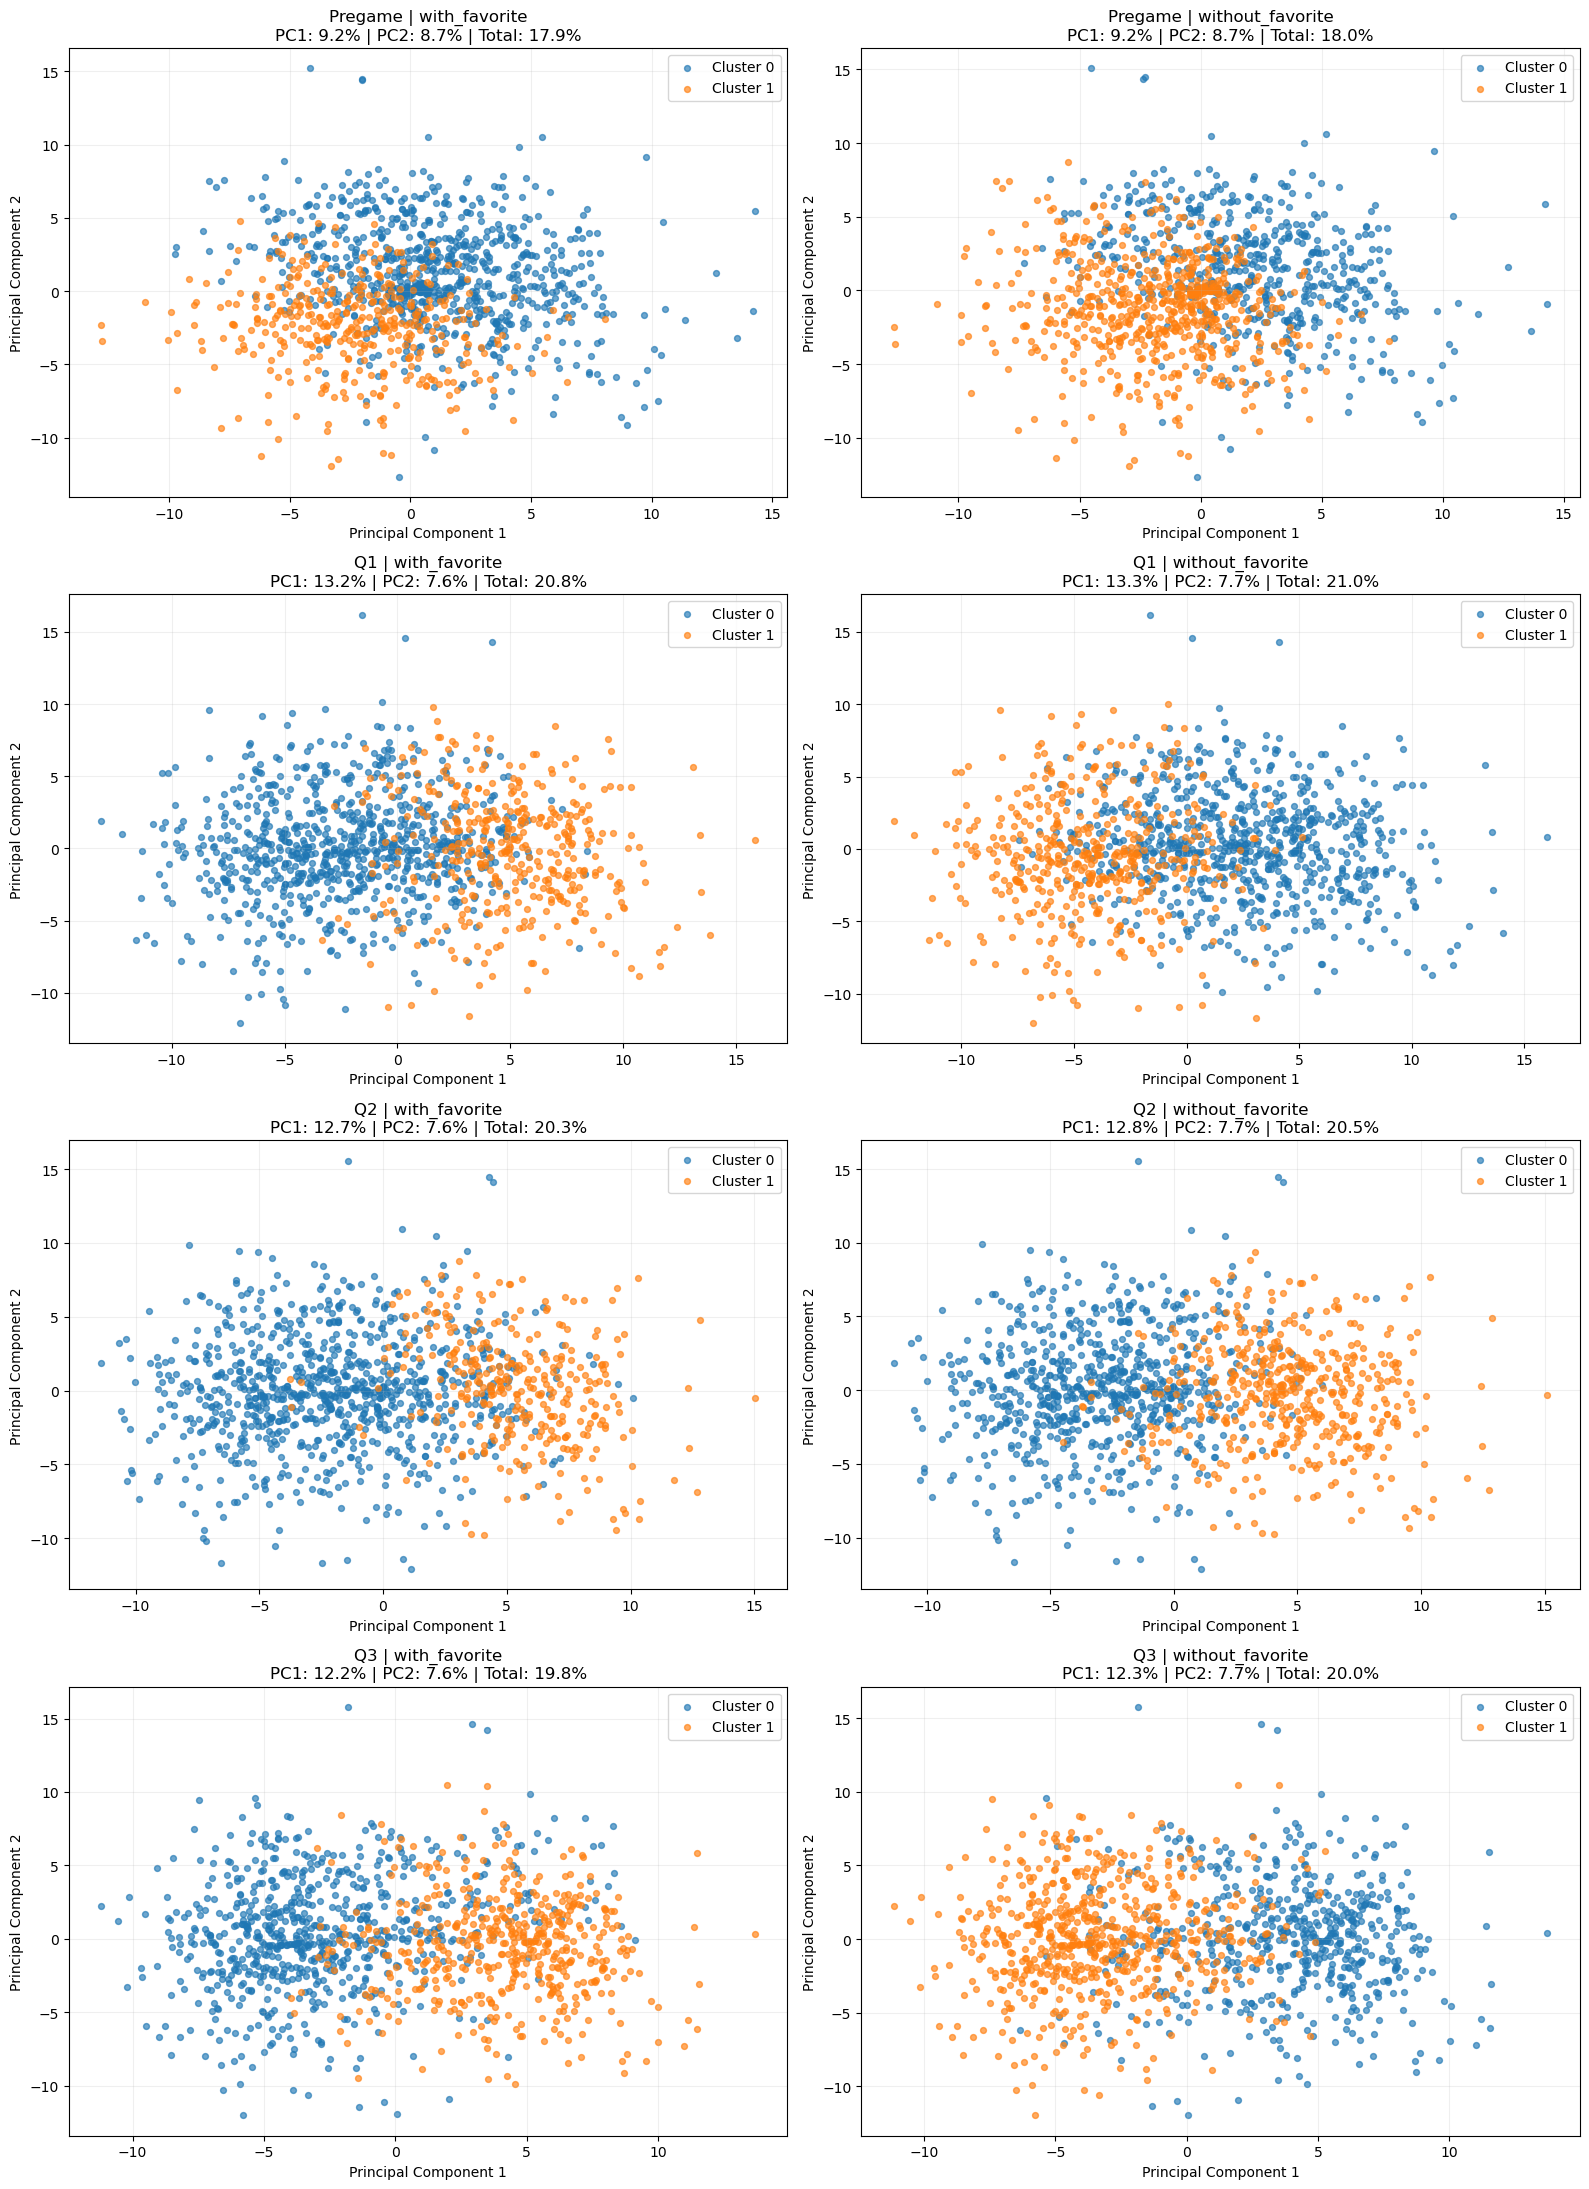

=== PCA EXPLAINED VARIANCE ===


,checkpoint,feature_set,PC1_variance_pct,PC2_variance_pct,total_variance_pct
0,Pregame,with_favorite,9.17,8.69,17.86
1,Pregame,without_favorite,9.22,8.73,17.95
2,Q1,with_favorite,13.22,7.61,20.83
3,Q1,without_favorite,13.32,7.69,21.01
4,Q2,with_favorite,12.67,7.60,20.27
5,Q2,without_favorite,12.79,7.68,20.47
6,Q3,with_favorite,12.17,7.58,19.75
7,Q3,without_favorite,12.29,7.66,19.96



Part 5B complete.
PCA visualizations generated for all eight feature sets.


In [39]:
# ============================================================
# PART 5B: PCA VISUALIZATION OF HIERARCHICAL CLUSTERS
# ============================================================

CHECKPOINTS = ["Pregame", "Q1", "Q2", "Q3"]
FEATURE_VARIANTS = ["with_favorite", "without_favorite"]
K_FOR_PLOTS = 2

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(16, 22)
)

pca_results = []

for row_idx, cp in enumerate(CHECKPOINTS):
    for col_idx, variant in enumerate(FEATURE_VARIANTS):

        ax = axes[row_idx, col_idx]

        prepared = feature_sets[cp][variant]
        X = prepared["X"]

        assignments = hierarchical_assignments[
            (cp, variant, K_FOR_PLOTS)
        ]

        game_ids = prepared["game_ids"]

        # Verify game ordering matches the cluster assignments.
        assert np.array_equal(
            np.asarray(game_ids),
            assignments["GAME_ID"].to_numpy()
        ), f"GAME_ID ordering mismatch for {cp}/{variant}"

        labels = assignments["cluster"].to_numpy()

        # Reduce standardized features to two dimensions.
        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X)

        explained = pca.explained_variance_ratio_ * 100
        total_explained = explained.sum()

        for cluster_id in np.unique(labels):
            mask = labels == cluster_id

            ax.scatter(
                X_pca[mask, 0],
                X_pca[mask, 1],
                s=18,
                alpha=0.65,
                label=f"Cluster {cluster_id}"
            )

        ax.set_title(
            f"{cp} | {variant}\n"
            f"PC1: {explained[0]:.1f}% | "
            f"PC2: {explained[1]:.1f}% | "
            f"Total: {total_explained:.1f}%"
        )

        ax.set_xlabel("Principal Component 1")
        ax.set_ylabel("Principal Component 2")
        ax.legend()
        ax.grid(alpha=0.2)

        pca_results.append({
            "checkpoint": cp,
            "feature_set": variant,
            "PC1_variance_pct": explained[0],
            "PC2_variance_pct": explained[1],
            "total_variance_pct": total_explained
        })

plt.tight_layout()
plt.show()

pca_results = pd.DataFrame(pca_results)

print("=== PCA EXPLAINED VARIANCE ===")
display(pca_results.round(2))

print("\nPart 5B complete.")
print("PCA visualizations generated for all eight feature sets.")

**Part 5B Results**

The PCA results show that the first two principal components explain approximately 17.9%–21.0% of total feature variance across the eight checkpoint and feature-set combinations. Q1 has the highest explained variance (21.0% without favorite-related features), while Pregame has the lowest (17.9% with favorite-related features). Excluding favorite-related features produces slightly higher explained variance at every checkpoint.

**Part 6A: Interpreting Clusters Using Feature Profiles**

This section interprets the two-cluster hierarchical clustering solutions across Pregame, Q1, Q2, and Q3, using both feature sets with and without favorite-related features. For each combination, it calculates cluster-level means and medians of standardized features, compares the mean values between clusters, and ranks features by the absolute difference in standardized means. It also summarizes the number and percentage of games assigned to each cluster. These profiles help identify which market indicators and team statistics distinguish the clusters at each checkpoint. 

In [42]:
# ============================================================
# PART 6A: INTERPRET CLUSTERS USING FEATURE PROFILES
# Requires feature_sets and hierarchical_assignments
# ============================================================

CHECKPOINTS = ["Pregame", "Q1", "Q2", "Q3"]
FEATURE_VARIANTS = ["with_favorite", "without_favorite"]
K_FOR_PROFILES = 2

cluster_profiles = {}
feature_separation = {}
cluster_profile_summary = []

for cp in CHECKPOINTS:
    for variant in FEATURE_VARIANTS:

        prepared = feature_sets[cp][variant]
        X = np.asarray(prepared["X"], dtype=float)
        feature_names = prepared["feature_names"]
        game_ids = np.asarray(prepared["game_ids"])

        assignments = hierarchical_assignments[
            (cp, variant, K_FOR_PROFILES)
        ]

        # Confirm game ordering matches the assignments.
        assert np.array_equal(
            game_ids,
            assignments["GAME_ID"].to_numpy()
        ), f"GAME_ID mismatch: {cp}/{variant}"

        labels = assignments["cluster"].to_numpy()

        assert X.shape[1] == len(feature_names)

        # Standardized feature matrix.
        X_df = pd.DataFrame(
            X,
            columns=feature_names
        )

        X_df["cluster"] = labels

        # Cluster means and medians in standardized units.
        means = X_df.groupby("cluster").mean()
        medians = X_df.groupby("cluster").median()

        cluster_profiles[(cp, variant)] = {
            "means": means,
            "medians": medians
        }

        # Difference in standardized means between clusters.
        differences = (
            means.loc[1] - means.loc[0]
        )

        separation = pd.DataFrame({
            "cluster_0_mean": means.loc[0],
            "cluster_1_mean": means.loc[1],
            "difference_1_minus_0": differences,
            "absolute_difference": differences.abs()
        }).sort_values(
            "absolute_difference",
            ascending=False
        )

        feature_separation[(cp, variant)] = separation

        # Save cluster sizes and standardized profile averages.
        sizes = pd.Series(labels).value_counts().sort_index()

        for cluster_id in means.index:
            cluster_profile_summary.append({
                "checkpoint": cp,
                "feature_set": variant,
                "cluster": int(cluster_id),
                "games": int(sizes.loc[cluster_id]),
                "cluster_pct": 100 * sizes.loc[cluster_id] / len(labels)
            })

        print(f"\n=== {cp} | {variant} ===")
        print("Cluster sizes:")
        display(
            pd.DataFrame({
                "games": sizes,
                "percentage": 100 * sizes / len(labels)
            }).round(2)
        )

        print("Top 15 features separating clusters:")
        display(separation.head(15).round(3))

cluster_profile_summary = pd.DataFrame(
    cluster_profile_summary
)

print("\n=== PART 6A: CLUSTER PROFILE SUMMARY ===")
display(
    cluster_profile_summary.round(2)
)

print("\nPart 6A complete.")
print("Cluster profiles saved in cluster_profiles.")
print("Feature differences saved in feature_separation.")


=== Pregame | with_favorite ===
Cluster sizes:


,games,percentage
0,831,67.84
1,394,32.16


Top 15 features separating clusters:


,cluster_0_mean,cluster_1_mean,difference_1_minus_0,absolute_difference
AWAY_ROLL5_5_game_roll_avg_PLUS_MINUS,0.330,-0.697,-1.027,1.027
AWAY_ROLL10_10_game_roll_avg_PLUS_MINUS,0.321,-0.676,-0.997,0.997
AWAY_ROLL10_10_game_roll_avg_FGM,0.317,-0.668,-0.984,0.984
AWAY_ROLL5_5_game_roll_avg_FGM,0.315,-0.664,-0.979,0.979
AWAY_ROLL15_15_game_roll_avg_PLUS_MINUS,0.300,-0.632,-0.931,0.931
AWAY_ROLL5_5_game_roll_avg_PTS,0.296,-0.625,-0.922,0.922
AWAY_ROLL10_10_game_roll_avg_PTS,0.293,-0.619,-0.912,0.912
AWAY_ROLL3_3_game_roll_avg_PLUS_MINUS,0.292,-0.616,-0.909,0.909
AWAY_ROLL10_10_game_roll_avg_REB,0.292,-0.615,-0.907,0.907
AWAY_ROLL15_15_game_roll_avg_REB,0.290,-0.611,-0.900,0.900



=== Pregame | without_favorite ===
Cluster sizes:


...

Top 15 features separating clusters:


,cluster_0_mean,cluster_1_mean,difference_1_minus_0,absolute_difference
Q3_AWAY_YES_BID_CLOSE,0.814,-0.722,-1.536,1.536
Q3_HOME_YES_ASK_LOW,-0.814,0.722,1.536,1.536
Q3_HOME_MID_PROB,-0.813,0.722,1.535,1.535
Q3_HOME_YES_BID_CLOSE,-0.813,0.722,1.535,1.535
Q3_HOME_YES_ASK_CLOSE,-0.813,0.722,1.535,1.535
Q3_AWAY_MID_PROB,0.813,-0.722,-1.535,1.535
Q3_AWAY_YES_BID_LOW,0.813,-0.722,-1.535,1.535
Q3_AWAY_YES_BID_HIGH,0.813,-0.722,-1.535,1.535
Q3_HOME_YES_ASK_OPEN,-0.813,0.722,1.535,1.535
Q3_HOME_YES_ASK_HIGH,-0.813,0.722,1.535,1.535



=== PART 6A: CLUSTER PROFILE SUMMARY ===


,checkpoint,feature_set,cluster,games,cluster_pct
0,Pregame,with_favorite,0,831,67.84
1,Pregame,with_favorite,1,394,32.16
2,Pregame,without_favorite,0,557,45.47
3,Pregame,without_favorite,1,668,54.53
4,Q1,with_favorite,0,830,67.76
5,Q1,with_favorite,1,395,32.24
6,Q1,without_favorite,0,770,62.86
7,Q1,without_favorite,1,455,37.14
8,Q2,with_favorite,0,895,73.06
9,Q2,with_favorite,1,330,26.94



Part 6A complete.
Cluster profiles saved in cluster_profiles.
Feature differences saved in feature_separation.


**Part 6A Results**

The cluster profiles reveal a consistent distinction between games with stronger versus weaker away-team recent performance in the Pregame analysis, where rolling averages for plus/minus, points, and field goals are the strongest separating features. From Q1 onward, current-quarter Kalshi market probabilities and bid/ask prices become the dominant features, with home- and away-team indicators generally moving in opposite directions. Cluster sizes vary by checkpoint and feature set, with the Q2 model including favorite-related features producing the most imbalanced split (73.1% vs. 26.9%). Excluding favorite-related features changes the cluster proportions and sometimes the balance of assignments, but the same broad market-driven separation persists.

**Part 6B: Heatmaps**

This section generates eight heatmaps to visualize the top 15 features distinguishing the two hierarchical clusters across Pregame, Q1, Q2, and Q3, using both feature sets. For each combination, the code aligns standardized feature values with cluster assignments by GAME_ID, calculates cluster-level mean values, and selects the 15 features with the largest absolute difference between clusters. The heatmaps use a diverging color scale centered at zero, making it easier to compare the direction and magnitude of feature differences. A summary table records the number of games analyzed, features displayed, and largest standardized difference for each model. 

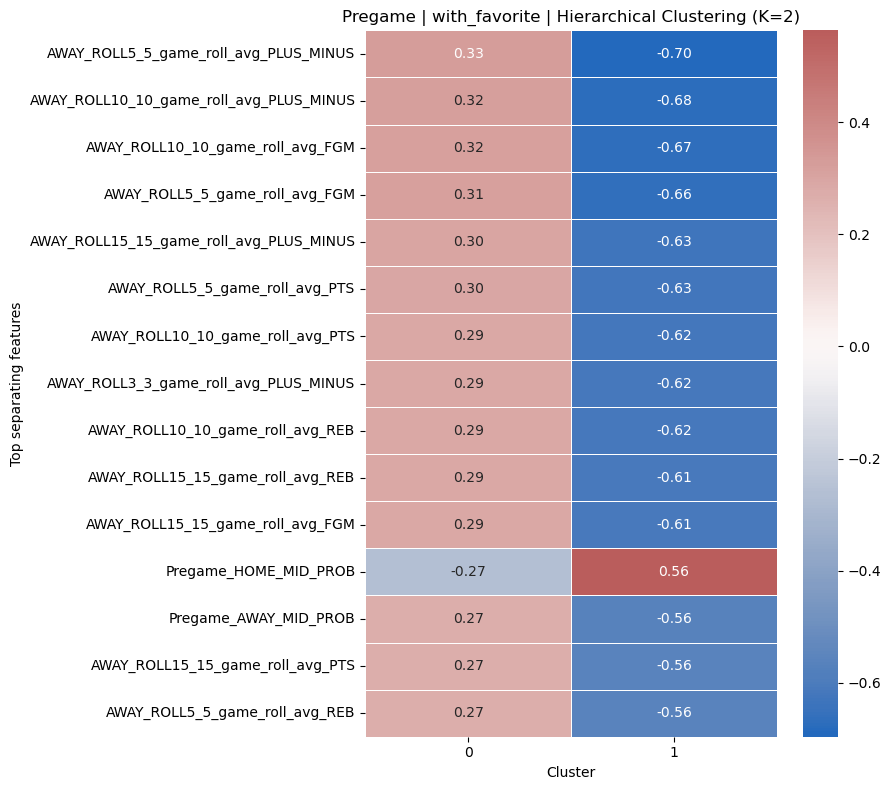

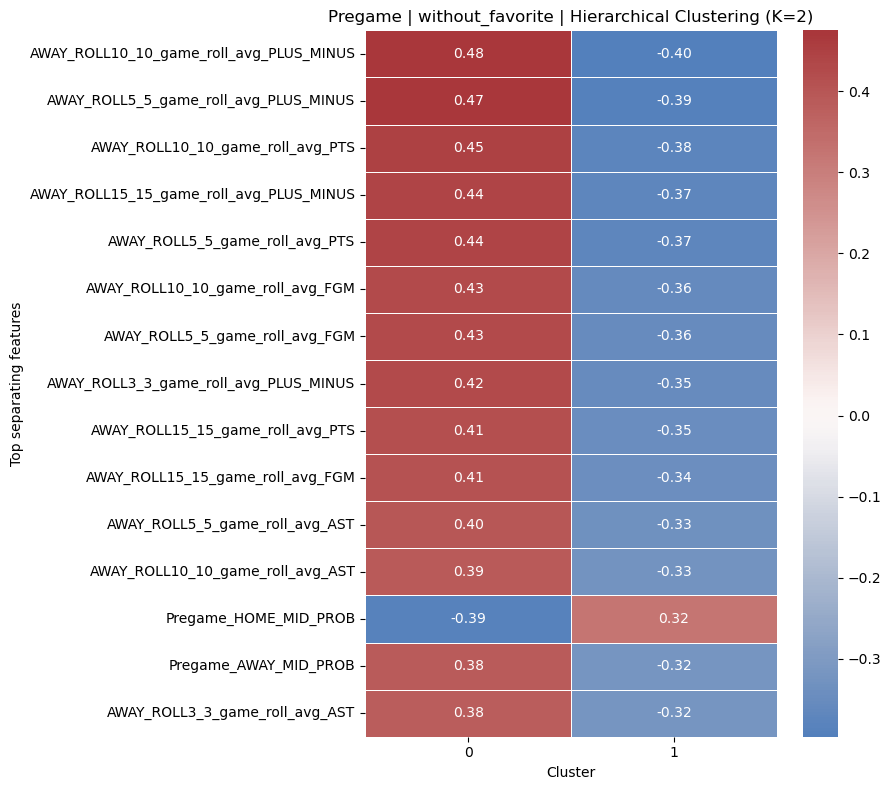

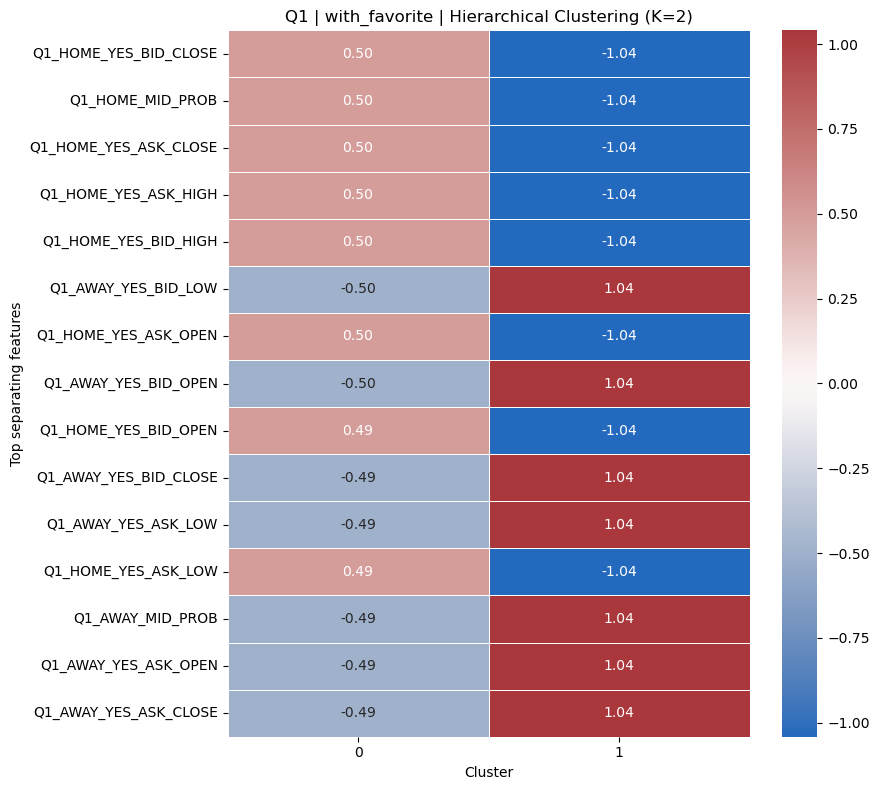

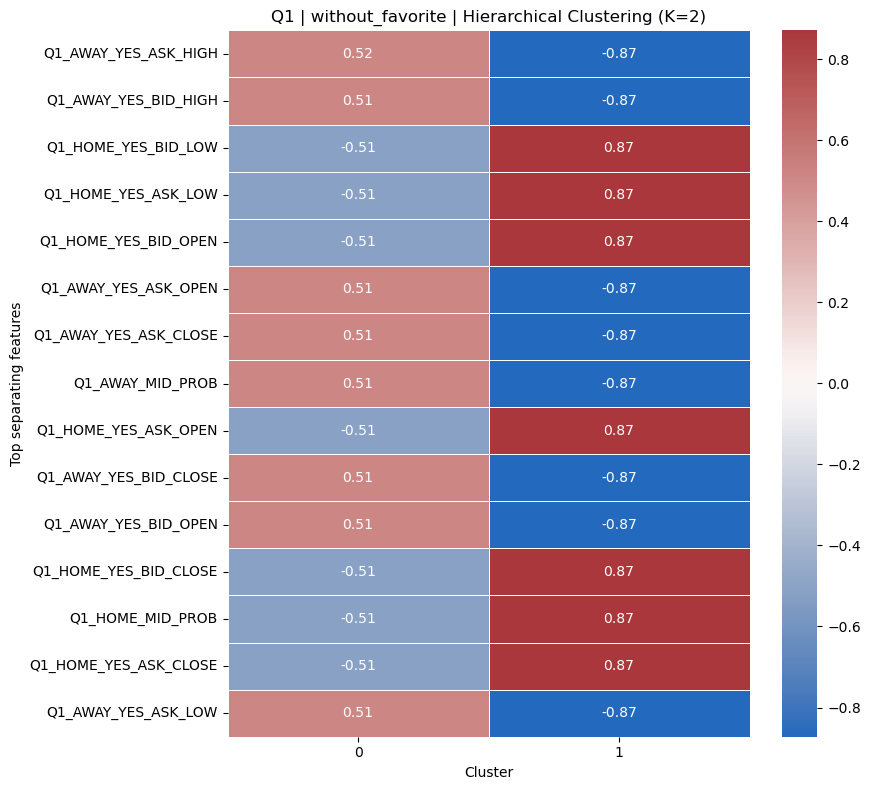

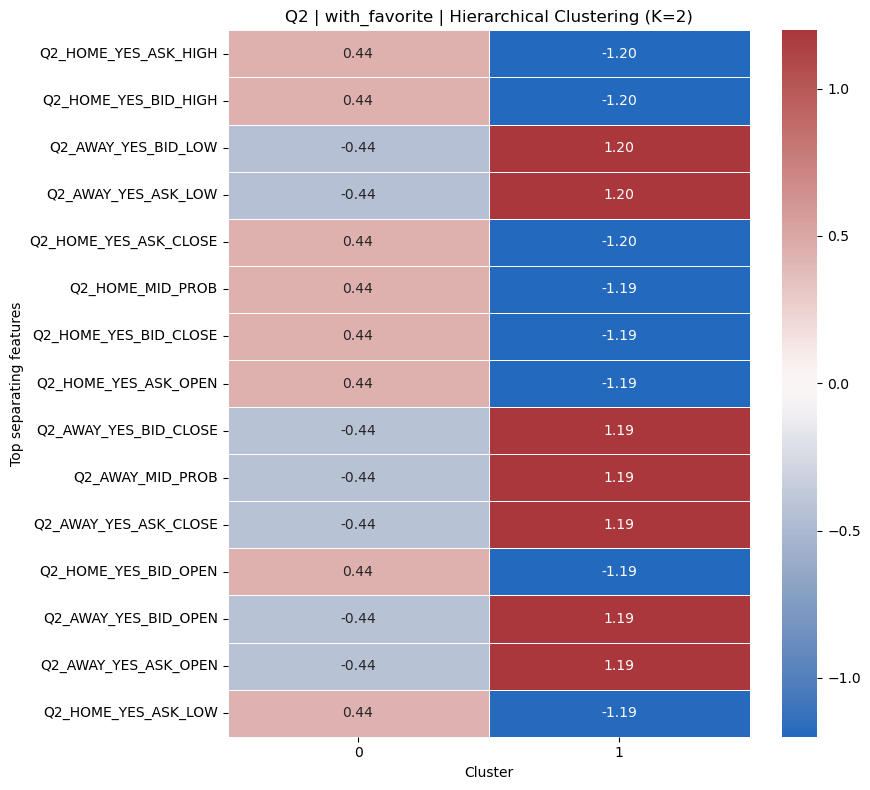

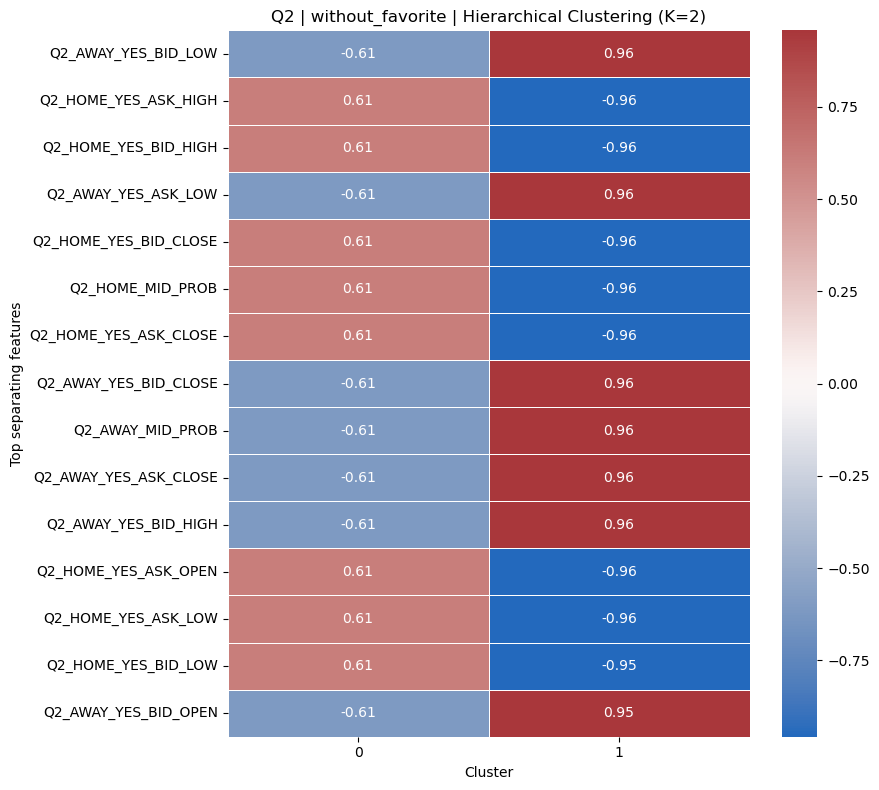

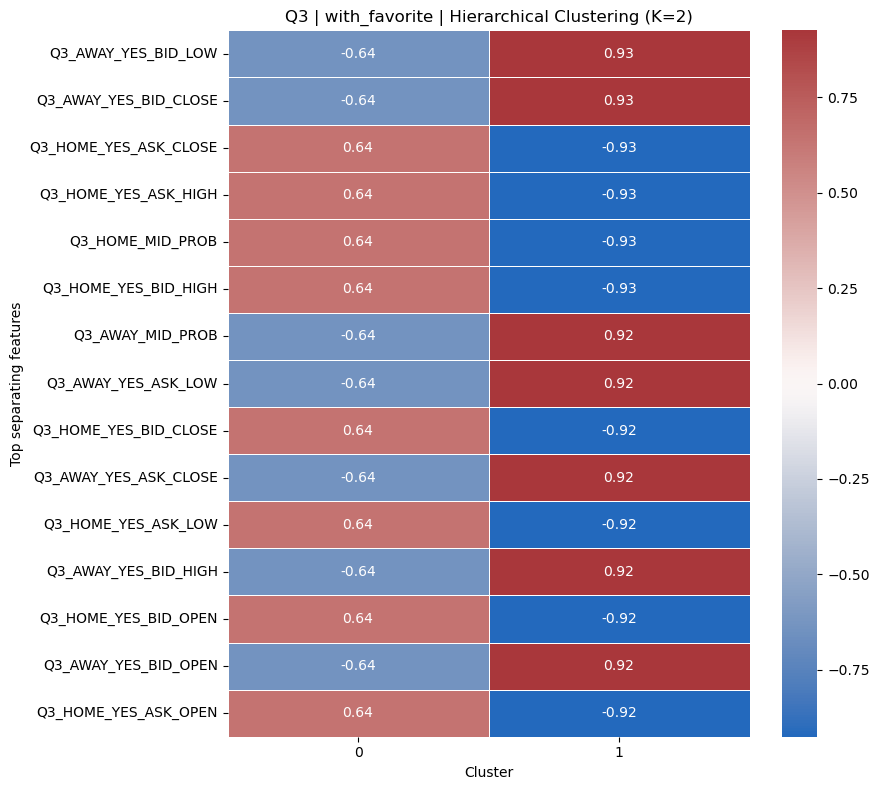

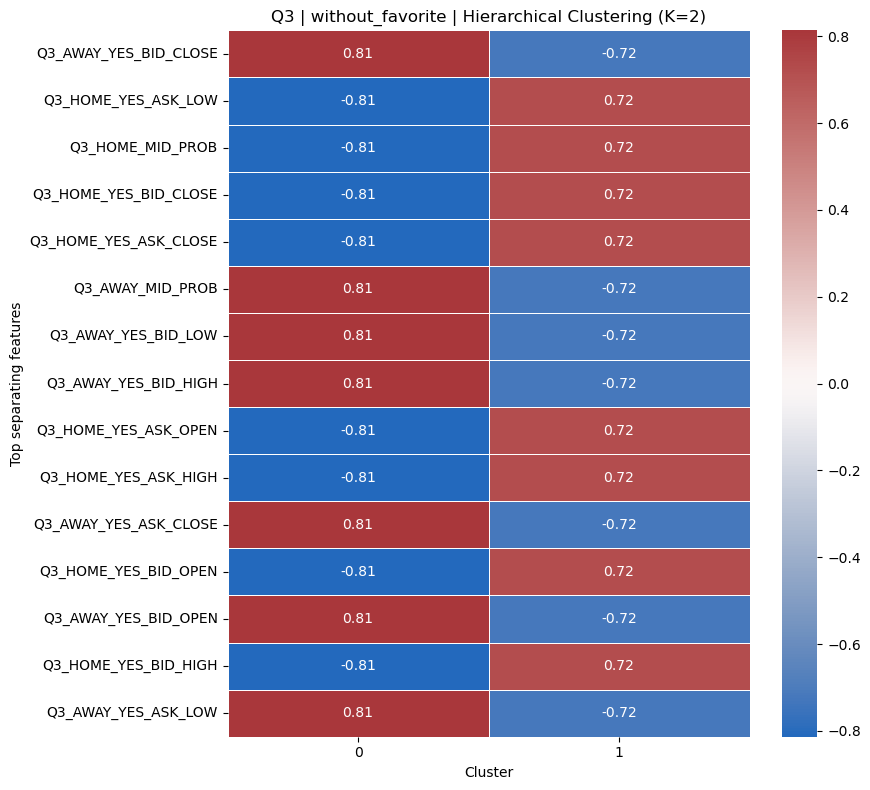

=== PART 6B: HEATMAP SUMMARY ===


,checkpoint,feature_set,games,features_displayed,largest_standardized_difference
0,Pregame,with_favorite,1225,15,1.0270
1,Pregame,without_favorite,1225,15,0.8712
2,Q1,with_favorite,1225,15,1.5369
3,Q1,without_favorite,1225,15,1.3874
4,Q2,with_favorite,1225,15,1.6422
5,Q2,without_favorite,1225,15,1.5663
6,Q3,with_favorite,1225,15,1.5635
7,Q3,without_favorite,1225,15,1.5356



Part 6B complete.
Heatmaps saved in the heatmap_data dictionary.


In [45]:
# ============================================================
# PART 6B: VISUALIZE CLUSTER PROFILES WITH HEATMAPS
# Uses existing feature_sets, hierarchical_assignments,
# cluster_profiles, and feature_separation
# ============================================================

CHECKPOINTS = ["Pregame", "Q1", "Q2", "Q3"]
FEATURE_VARIANTS = ["with_favorite", "without_favorite"]
K = 2
TOP_N = 15

heatmap_data = {}
heatmap_summary = []

for cp in CHECKPOINTS:
    for variant in FEATURE_VARIANTS:

        key = (cp, variant, K)

        # Retrieve the prepared feature matrix and labels.
        X_info = feature_sets[cp][variant]
        X = X_info["X"]
        feature_names = X_info["feature_names"]

        assignments = hierarchical_assignments[key]

        # Align rows by GAME_ID rather than assuming row order.
        X_df = pd.DataFrame(
            X,
            columns=feature_names
        )
        X_df["GAME_ID"] = X_info["game_ids"]

        labels = assignments[["GAME_ID", "cluster"]].copy()

        merged = X_df.merge(
            labels,
            on="GAME_ID",
            how="inner",
            validate="one_to_one"
        )

        # Cluster means are in standardized feature units.
        cluster_means = merged.groupby("cluster")[
            feature_names
        ].mean()

        # Rank features by the absolute difference between clusters.
        differences = (
            cluster_means.loc[1] - cluster_means.loc[0]
        ).abs().sort_values(ascending=False)

        top_features = differences.head(TOP_N).index.tolist()

        profile = cluster_means[top_features].T
        heatmap_data[key] = profile

        heatmap_summary.append({
            "checkpoint": cp,
            "feature_set": variant,
            "games": len(merged),
            "features_displayed": len(top_features),
            "largest_standardized_difference": differences.iloc[0]
        })

        fig, ax = plt.subplots(figsize=(9, 8))

        sns.heatmap(
            profile,
            annot=True,
            fmt=".2f",
            cmap="vlag",
            center=0,
            linewidths=0.4,
            ax=ax
        )

        ax.set_title(
            f"{cp} | {variant} | Hierarchical Clustering (K=2)"
        )
        ax.set_xlabel("Cluster")
        ax.set_ylabel("Top separating features")

        plt.tight_layout()
        plt.show()

print("=== PART 6B: HEATMAP SUMMARY ===")
display(pd.DataFrame(heatmap_summary).round(4))

print("\nPart 6B complete.")
print("Heatmaps saved in the heatmap_data dictionary.")

**Part 6B Results**

The heatmap analysis covered all 1,225 games across the eight checkpoint and feature-set combinations, displaying the 15 features with the largest differences between clusters in each case. The largest standardized feature separation increased from Pregame (1.027 with favorite-related features) to Q1 (1.537) and peaked at Q2 (1.642), before remaining strong in Q3 (1.564). Excluding favorite-related features produced slightly smaller maximum differences at every checkpoint, although the overall pattern remained similar.

**Part 6C: Evaluating Hierarchical Clusters Against Outcomes**

This section evaluates whether the two-cluster hierarchical models distinguish games with different outcomes. It merges cluster assignments with the binary away-team win indicator, calculates away- and home-win rates for each cluster, and measures outcome separation as the absolute difference in away-win rates. It then compares this separation between hierarchical clustering and K-means across all four checkpoints (Pregame, Q1, Q2, and Q3) and both feature variants. 

In [48]:
# ============================================================
# PART 6C: EVALUATE HIERARCHICAL CLUSTERS AGAINST OUTCOMES
# Requires:
#   hierarchical_assignments
#   cluster_assignments
#   An outcome table with GAME_ID and away-team win indicator
# ============================================================

CHECKPOINTS = ["Pregame", "Q1", "Q2", "Q3"]
FEATURE_VARIANTS = ["with_favorite", "without_favorite"]
K = 2

# ------------------------------------------------------------
# 1. IDENTIFY THE OUTCOME TABLE
# ------------------------------------------------------------

# Inspect likely outcome variables.
candidate_tables = {
    name: obj
    for name, obj in globals().copy().items()
    if isinstance(obj, pd.DataFrame)
    and "GAME_ID" in obj.columns
    and len(obj) == obj["GAME_ID"].nunique()
}

print("Potential outcome tables:")
for name, table in candidate_tables.items():
    outcome_cols = [
        c for c in table.columns
        if any(term in c.upper() for term in
               ["WIN", "OUTCOME", "RESULT", "HOME_SCORE", "AWAY_SCORE"])
    ]
    if outcome_cols:
        print(name, "|", outcome_cols)


if "outcomes" in globals() and isinstance(outcomes, pd.DataFrame):
    outcome_table = outcomes.copy()
elif "game_outcomes" in globals() and isinstance(game_outcomes, pd.DataFrame):
    outcome_table = game_outcomes.copy()
else:
    raise NameError(
        "Set outcome_table = your_existing_outcome_dataframe.copy() "
        "using one of the candidate tables printed above."
    )

# ------------------------------------------------------------
# 2. IDENTIFY / STANDARDIZE THE AWAY-WIN COLUMN
# ------------------------------------------------------------

print("\nOutcome table columns:")
print(outcome_table.columns.tolist())

# Set this explicitly if automatic detection is not correct.
AWAY_WIN_COL = None

if AWAY_WIN_COL is None:
    possible_cols = [
        c for c in outcome_table.columns
        if c.upper() in [
            "AWAY_WIN", "AWAY_WON", "AWAY_TEAM_WIN",
            "AWAY_WIN_INDICATOR", "AWAY_WIN_FLAG"
        ]
    ]

    if len(possible_cols) == 1:
        AWAY_WIN_COL = possible_cols[0]
    else:
        raise ValueError(
            "Set AWAY_WIN_COL to the correct binary away-win column. "
            f"Candidate columns: {possible_cols}"
        )

outcome_table = outcome_table[["GAME_ID", AWAY_WIN_COL]].copy()
outcome_table = outcome_table.rename(
    columns={AWAY_WIN_COL: "AWAY_WIN"}
)

assert outcome_table["GAME_ID"].is_unique, (
    "Outcome table must contain one row per GAME_ID."
)

# Validate binary outcome coding.
outcome_values = set(outcome_table["AWAY_WIN"].dropna().unique())
assert outcome_values.issubset({0, 1, False, True}), (
    f"Expected binary 0/1 away-win outcomes; found {outcome_values}"
)

# ------------------------------------------------------------
# 3. CALCULATE HIERARCHICAL CLUSTER OUTCOME RATES
# ------------------------------------------------------------

hierarchical_rows = []

for cp in CHECKPOINTS:
    for variant in FEATURE_VARIANTS:

        key = (cp, variant, K)

        if key not in hierarchical_assignments:
            print("Skipping missing hierarchical model:", key)
            continue

        assignments = hierarchical_assignments[key].copy()

        merged = assignments.merge(
            outcome_table,
            on="GAME_ID",
            how="left",
            validate="one_to_one"
        )

        for cluster_id, group in merged.groupby("cluster"):

            known = group["AWAY_WIN"].dropna()

            hierarchical_rows.append({
                "checkpoint": cp,
                "feature_set": variant,
                "k": K,
                "cluster": int(cluster_id),
                "games": len(group),
                "known_outcomes": len(known),
                "away_win_rate": known.mean(),
                "home_win_rate": 1 - known.mean()
                    if len(known) else np.nan
            })

hierarchical_outcomes = pd.DataFrame(hierarchical_rows)

print("\n=== HIERARCHICAL CLUSTER OUTCOME RATES ===")
display(hierarchical_outcomes.round(4))

# ------------------------------------------------------------
# 4. MEASURE OUTCOME SEPARATION
# ------------------------------------------------------------

separation_rows = []

for (cp, variant, k), group in hierarchical_outcomes.groupby(
    ["checkpoint", "feature_set", "k"]
):
    if group["cluster"].nunique() != 2:
        continue

    rates = group.set_index("cluster")["away_win_rate"]

    if 0 not in rates.index or 1 not in rates.index:
        continue

    separation_rows.append({
        "checkpoint": cp,
        "feature_set": variant,
        "k": k,
        "cluster_0_away_win_rate": rates.loc[0],
        "cluster_1_away_win_rate": rates.loc[1],
        "absolute_win_rate_difference": abs(
            rates.loc[1] - rates.loc[0]
        )
    })

hierarchical_separation = pd.DataFrame(separation_rows)

hierarchical_separation = hierarchical_separation.sort_values(
    "absolute_win_rate_difference",
    ascending=False
).reset_index(drop=True)

print("\n=== HIERARCHICAL OUTCOME SEPARATION ===")
display(hierarchical_separation.round(4))

# ------------------------------------------------------------
# 5. COMPARE AGAINST K-MEANS CLUSTERING
# ------------------------------------------------------------

kmeans_rows = []

for cp in CHECKPOINTS:
    for variant in FEATURE_VARIANTS:

        key = (cp, variant, K)

        if key not in cluster_assignments:
            print("Skipping missing K-means model:", key)
            continue

        assignments = cluster_assignments[key].copy()

        merged = assignments.merge(
            outcome_table,
            on="GAME_ID",
            how="left",
            validate="one_to_one"
        )

        for cluster_id, group in merged.groupby("cluster"):

            known = group["AWAY_WIN"].dropna()

            kmeans_rows.append({
                "checkpoint": cp,
                "feature_set": variant,
                "cluster": int(cluster_id),
                "games": len(group),
                "away_win_rate": known.mean()
            })

kmeans_outcomes = pd.DataFrame(kmeans_rows)

# Cluster numbers are arbitrary. Compare the spread of cluster
# win rates rather than assuming cluster 0 in one method matches
# cluster 0 in the other.
def outcome_spread(group):
    rates = group["away_win_rate"].dropna()
    return rates.max() - rates.min() if len(rates) >= 2 else np.nan

hier_spread = (
    hierarchical_outcomes
    .groupby(["checkpoint", "feature_set"])
    .apply(outcome_spread, include_groups=False)
    .rename("hierarchical_win_rate_spread")
    .reset_index()
)

kmeans_spread = (
    kmeans_outcomes
    .groupby(["checkpoint", "feature_set"])
    .apply(outcome_spread, include_groups=False)
    .rename("kmeans_win_rate_spread")
    .reset_index()
)

method_comparison = hier_spread.merge(
    kmeans_spread,
    on=["checkpoint", "feature_set"],
    how="outer",
    validate="one_to_one"
)

print("\n=== HIERARCHICAL VS K-MEANS ===")
display(method_comparison.round(4))

# ------------------------------------------------------------
# 6. SAVE RESULTS IN MEMORY
# ------------------------------------------------------------

print("\nPart 6C complete.")
print("Results saved in:")
print("- hierarchical_outcomes")
print("- hierarchical_separation")
print("- kmeans_outcomes")
print("- method_comparison")

Potential outcome tables:
frame | ['WINNER']
main | ['WINNER']
metadata | ['WINNER']
merged_base | ['WINNER']
part | ['WINNER', 'AWAY_WIN']
outcomes | ['WINNER', 'AWAY_WIN']

Outcome table columns:
['GAME_ID', 'WINNER', 'AWAY_WIN']

=== HIERARCHICAL CLUSTER OUTCOME RATES ===


,checkpoint,feature_set,k,cluster,games,known_outcomes,away_win_rate,home_win_rate
0,Pregame,with_favorite,2,0,831,831,0.5102,0.4898
1,Pregame,with_favorite,2,1,394,394,0.3096,0.6904
2,Pregame,without_favorite,2,0,557,557,0.5494,0.4506
3,Pregame,without_favorite,2,1,668,668,0.3593,0.6407
4,Q1,with_favorite,2,0,830,830,0.3217,0.6783
5,Q1,with_favorite,2,1,395,395,0.7063,0.2937
6,Q1,without_favorite,2,0,770,770,0.5844,0.4156
7,Q1,without_favorite,2,1,455,455,0.2110,0.7890
8,Q2,with_favorite,2,0,895,895,0.3151,0.6849
9,Q2,with_favorite,2,1,330,330,0.8000,0.2000



=== HIERARCHICAL OUTCOME SEPARATION ===


,checkpoint,feature_set,k,cluster_0_away_win_rate,cluster_1_away_win_rate,absolute_win_rate_difference
0,Q3,with_favorite,2,0.2179,0.7760,0.5581
1,Q3,without_favorite,2,0.7309,0.1926,0.5383
2,Q2,without_favorite,2,0.2550,0.7458,0.4908
3,Q2,with_favorite,2,0.3151,0.8000,0.4849
4,Q1,with_favorite,2,0.3217,0.7063,0.3846
5,Q1,without_favorite,2,0.5844,0.2110,0.3734
6,Pregame,with_favorite,2,0.5102,0.3096,0.2006
7,Pregame,without_favorite,2,0.5494,0.3593,0.1901



=== HIERARCHICAL VS K-MEANS ===


,checkpoint,feature_set,hierarchical_win_rate_spread,kmeans_win_rate_spread
0,Pregame,with_favorite,0.2006,0.2228
1,Pregame,without_favorite,0.1901,0.2239
2,Q1,with_favorite,0.3846,0.4245
3,Q1,without_favorite,0.3734,0.4288
4,Q2,with_favorite,0.4849,0.5309
5,Q2,without_favorite,0.4908,0.5324
6,Q3,with_favorite,0.5581,0.6662
7,Q3,without_favorite,0.5383,0.6595



Part 6C complete.
Results saved in:
- hierarchical_outcomes
- hierarchical_separation
- kmeans_outcomes
- method_comparison


**Part 6C Results**

The hierarchical clustering results show that outcome separation improves as the game progresses. Pregame clusters have relatively small differences in away-team win rates (19.0–20.1 percentage points), increasing to 37.3–38.5 points after Q1, 48.5–49.1 points after Q2, and 53.8–55.8 points after Q3. The strongest separation occurs with the Q3 model using the favorite-inclusive feature set, where away-team win rates are 21.8% and 77.6% across the two clusters. However, K-means produces greater outcome separation than hierarchical clustering for every checkpoint and feature variant, reaching a maximum difference of 66.6 percentage points for Q3 with favorite-inclusive features. 

**Part 7A Preparing Kalshi Probabilities and Game Outcomes**

This section prepares the data for evaluating Kalshi market probabilities against actual game outcomes. It validates the outcome table, converts game IDs to strings, ensures the away-win indicator is numeric and binary, removes invalid outcomes, and checks that each game appears only once. It then inspects the available probability-related features across all four checkpoints (Pregame, Q1, Q2, and Q3) and both feature variants. 

In [51]:
# ============================================================
# PART 7A: PREPARE KALSHI PROBABILITIES AND GAME OUTCOMES
# ============================================================

# ------------------------------------------------------------
# 1. Inspect outcome data
# ------------------------------------------------------------

print("Outcome columns:", outcomes.columns.tolist())
print("Outcome observations:", len(outcomes))

assert "GAME_ID" in outcomes.columns, "outcomes needs GAME_ID."
assert "AWAY_WIN" in outcomes.columns, "outcomes needs AWAY_WIN."

outcome_df = outcomes[["GAME_ID", "AWAY_WIN"]].copy()

outcome_df["GAME_ID"] = outcome_df["GAME_ID"].astype(str)
outcome_df["AWAY_WIN"] = pd.to_numeric(
    outcome_df["AWAY_WIN"], errors="coerce"
)

outcome_df = outcome_df.dropna(subset=["AWAY_WIN"])
outcome_df = outcome_df[
    outcome_df["AWAY_WIN"].isin([0, 1])
].copy()

assert outcome_df["GAME_ID"].is_unique, (
    "Outcome table has duplicate GAME_ID values. Resolve these first."
)

print("\nValid outcomes:", len(outcome_df))
print("Away wins:", int(outcome_df["AWAY_WIN"].sum()))
print("Home wins:", int((1 - outcome_df["AWAY_WIN"]).sum()))

# ------------------------------------------------------------
# 2. Inspect available probability features
# ------------------------------------------------------------

for cp in ["Pregame", "Q1", "Q2", "Q3"]:
    for variant in ["with_favorite", "without_favorite"]:
        fs = feature_sets[cp][variant]
        names = fs["feature_names"]

        probability_features = [
            name for name in names
            if "MID_PROB" in name.upper()
            or "PROB" in name.upper()
        ]

        print(f"\n{cp} | {variant}")
        print(probability_features[:30])

Outcome columns: ['GAME_ID', 'WINNER', 'AWAY_WIN']
Outcome observations: 1225

Valid outcomes: 1225
Away wins: 546
Home wins: 679

Pregame | with_favorite
['Pregame_AWAY_MID_PROB', 'Pregame_HOME_MID_PROB', 'Pregame_AWAY_PROB_DISTANCE_FROM_50']

Pregame | without_favorite
['Pregame_AWAY_MID_PROB', 'Pregame_HOME_MID_PROB', 'Pregame_AWAY_PROB_DISTANCE_FROM_50']

Q1 | with_favorite
['Q1_AWAY_MID_PROB', 'Q1_HOME_MID_PROB', 'Q1_FAVORITE_PROB', 'Q1_AWAY_PROB_DISTANCE_FROM_50', 'Q1_AWAY_PROB_MOVEMENT', 'Q1_ABS_AWAY_PROB_MOVEMENT']

Q1 | without_favorite
['Q1_AWAY_MID_PROB', 'Q1_HOME_MID_PROB', 'Q1_AWAY_PROB_DISTANCE_FROM_50', 'Q1_AWAY_PROB_MOVEMENT', 'Q1_ABS_AWAY_PROB_MOVEMENT']

Q2 | with_favorite
['Q2_AWAY_MID_PROB', 'Q2_HOME_MID_PROB', 'Q2_FAVORITE_PROB', 'Q2_AWAY_PROB_DISTANCE_FROM_50', 'Q2_AWAY_PROB_MOVEMENT', 'Q2_ABS_AWAY_PROB_MOVEMENT']

Q2 | without_favorite
['Q2_AWAY_MID_PROB', 'Q2_HOME_MID_PROB', 'Q2_AWAY_PROB_DISTANCE_FROM_50', 'Q2_AWAY_PROB_MOVEMENT', 'Q2_ABS_AWAY_PROB_MOVEMENT']



**Part 7A Results**

The outcome dataset contains 1,225 unique games with complete, valid results: 546 away-team wins (44.6%) and 679 home-team wins (55.4%). Probability features are available for all four checkpoints—Pregame, Q1, Q2, and Q3—including the away- and home-team midpoint probabilities. In-game checkpoints also include away-team probability distance from 50% and probability movement measures. These features provide the inputs needed to evaluate how accurately Kalshi market probabilities reflect actual outcomes at different stages of a game.

**Part 7B: Checking Probability**

This section verifies the scale of the Kalshi probability features. For each checkpoint (Pregame, Q1, Q2, and Q3) and feature variant, it retrieves the standardized away- and home-team midpoint probabilities and reverses the scaling transformation using the fitted scaler. It then reports the reconstructed minimum, maximum, mean, and first ten values to check whether the original probabilities are on a 0–1 or 0–100 scale.

In [54]:
# ============================================================
# PART 7B: CHECK PROBABILITY
# ============================================================

for cp in ["Pregame", "Q1", "Q2", "Q3"]:
    for variant in ["with_favorite", "without_favorite"]:

        fs = feature_sets[cp][variant]
        names = fs["feature_names"]
        X_scaled = fs["X"]
        scaler = fs["scaler"]

        print(f"\n{'=' * 60}")
        print(f"{cp} | {variant}")

        for col in [
            f"{cp}_AWAY_MID_PROB",
            f"{cp}_HOME_MID_PROB"
        ]:
            if col not in names:
                print(f"{col}: not found")
                continue

            j = names.index(col)
            z = X_scaled[:, j]

            # Invert standardization for this feature.
            original = z * scaler.scale_[j] + scaler.mean_[j]

            print(f"\nFeature: {col}")
            print("Scaled min/max:",
                  round(float(np.min(z)), 4),
                  round(float(np.max(z)), 4))
            print("Reconstructed min/max:",
                  round(float(np.min(original)), 4),
                  round(float(np.max(original)), 4))
            print("Reconstructed mean:",
                  round(float(np.mean(original)), 4))
            print("First 10 values:",
                  np.round(original[:10], 4).tolist())


Pregame | with_favorite

Feature: Pregame_AWAY_MID_PROB
Scaled min/max: -1.8737 2.2519
Reconstructed min/max: 0.025 0.965
Reconstructed mean: 0.4519
First 10 values: [0.565, 0.34, 0.195, 0.545, 0.245, 0.34, 0.345, 0.615, 0.38, 0.4]

Feature: Pregame_HOME_MID_PROB
Scaled min/max: -2.2634 1.8587
Reconstructed min/max: 0.035 0.975
Reconstructed mean: 0.5511
First 10 values: [0.445, 0.685, 0.805, 0.455, 0.755, 0.66, 0.66, 0.385, 0.64, 0.6]

Pregame | without_favorite

Feature: Pregame_AWAY_MID_PROB
Scaled min/max: -1.8737 2.2519
Reconstructed min/max: 0.025 0.965
Reconstructed mean: 0.4519
First 10 values: [0.565, 0.34, 0.195, 0.545, 0.245, 0.34, 0.345, 0.615, 0.38, 0.4]

Feature: Pregame_HOME_MID_PROB
Scaled min/max: -2.2634 1.8587
Reconstructed min/max: 0.035 0.975
Reconstructed mean: 0.5511
First 10 values: [0.445, 0.685, 0.805, 0.455, 0.755, 0.66, 0.66, 0.385, 0.64, 0.6]

Q1 | with_favorite

Feature: Q1_AWAY_MID_PROB
Scaled min/max: -1.7134 2.0847
Reconstructed min/max: 0.005 0.995
Re

**Part 7B Results**

Pregame away-team probabilities range from 0.025 to 0.965, while probabilities at Q1, Q2, and Q3 range from 0.005 to 0.995. Across checkpoints, the mean away-team probability remains approximately 45.2–45.6%, while the mean home-team probability is approximately 54.6–55.1%, consistent with the overall tendency toward more home-team wins in the dataset.

**Part 7C: Kalshi Forecast Evaluation by Cluster**

This section evaluates Kalshi's away-team win probabilities against actual game outcomes at Pregame, Q1, Q2, and Q3, using both feature variants. After reconstructing the original probabilities and validating their alignment with game outcomes, it calculates forecast accuracy, Brier score, log loss, mean predicted away-win probability, actual away-win rate, and calibration gap. These metrics are reported for all games combined and separately for each cluster produced by K-means and hierarchical clustering with k=2. The section also groups predictions into ten probability bins to compare predicted probabilities with observed away-team win rates. This analysis assesses overall forecast quality and whether market probabilities perform differently across distinct game-state clusters.

In [57]:
# ============================================================
# PART 7C: KALSHI FORECAST EVALUATION BY CLUSTER
# Metrics: Accuracy, Brier score, log loss, calibration
# ============================================================

CHECKPOINTS = ["Pregame", "Q1", "Q2", "Q3"]
VARIANTS = ["with_favorite", "without_favorite"]
K = 2

# ------------------------------------------------------------
# 1. Prepare outcomes
# ------------------------------------------------------------

outcome_df = outcomes[["GAME_ID", "AWAY_WIN"]].copy()
outcome_df["GAME_ID"] = outcome_df["GAME_ID"].astype(str)
outcome_df["AWAY_WIN"] = pd.to_numeric(
    outcome_df["AWAY_WIN"], errors="coerce"
)
outcome_df = outcome_df.dropna(subset=["AWAY_WIN"])
outcome_df = outcome_df[
    outcome_df["AWAY_WIN"].isin([0, 1])
].copy()

assert outcome_df["GAME_ID"].is_unique

# ------------------------------------------------------------
# 2. Metric helper
# ------------------------------------------------------------

def evaluate_forecasts(y, p):
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=float)

    valid = np.isfinite(y) & np.isfinite(p)
    y, p = y[valid], p[valid]

    if len(y) == 0:
        return {
            "games": 0,
            "accuracy": np.nan,
            "brier_score": np.nan,
            "log_loss": np.nan,
            "mean_predicted_away_win": np.nan,
            "actual_away_win_rate": np.nan,
            "calibration_gap": np.nan
        }

    # Avoid undefined log loss at exactly 0 or 1.
    p = np.clip(p, 1e-15, 1 - 1e-15)

    return {
        "games": len(y),
        "accuracy": accuracy_score(y, (p >= 0.5).astype(int)),
        "brier_score": brier_score_loss(y, p),
        "log_loss": log_loss(y, p, labels=[0, 1]),
        "mean_predicted_away_win": p.mean(),
        "actual_away_win_rate": y.mean(),
        "calibration_gap": abs(p.mean() - y.mean())
    }

# ------------------------------------------------------------
# 3. Evaluate each checkpoint and clustering method
# ------------------------------------------------------------

results = []
calibration_records = []

for cp in CHECKPOINTS:
    for variant in VARIANTS:

        fs = feature_sets[cp][variant]
        names = fs["feature_names"]
        X_scaled = fs["X"]
        scaler = fs["scaler"]
        game_ids = pd.Series(
            fs["game_ids"].astype(str), name="GAME_ID"
        )

        prob_col = f"{cp}_AWAY_MID_PROB"

        if prob_col not in names:
            print(f"Skipping missing probability: {prob_col}")
            continue

        j = names.index(prob_col)

        # Recover original decimal probabilities.
        p = (
            X_scaled[:, j] * scaler.scale_[j]
            + scaler.mean_[j]
        )

        # Verify that reconstructed values are probabilities.
        if p.min() < -1e-6 or p.max() > 1 + 1e-6:
            raise ValueError(
                f"{cp}/{variant}: reconstructed probabilities "
                f"outside [0,1]: {p.min():.4f}, {p.max():.4f}"
            )

        p = np.clip(p, 0, 1)

        pred_df = pd.DataFrame({
            "GAME_ID": game_ids,
            "p_away": p
        })

        # Verify row-to-game alignment.
        assert pred_df["GAME_ID"].is_unique, (
            f"Duplicate game IDs in {cp}/{variant}"
        )

        merged = pred_df.merge(
            outcome_df, on="GAME_ID", how="inner",
            validate="one_to_one"
        )

        assert len(merged) == len(pred_df), (
            f"Some games did not match outcomes: {cp}/{variant}"
        )

        # ----------------------------------------------------
        # Overall forecast metrics
        # ----------------------------------------------------

        overall = evaluate_forecasts(
            merged["AWAY_WIN"], merged["p_away"]
        )

        results.append({
            "checkpoint": cp,
            "feature_set": variant,
            "method": "Overall",
            "cluster": "All",
            **overall
        })

        # ----------------------------------------------------
        # K-means and hierarchical cluster metrics
        # ----------------------------------------------------

        assignments_to_check = [
            ("KMeans", cluster_assignments),
            ("Hierarchical", hierarchical_assignments)
        ]

        for method, assignments in assignments_to_check:
            key = (cp, variant, K)

            if key not in assignments:
                print(f"Missing assignments: {method} {key}")
                continue

            labels_df = assignments[key].copy()
            labels_df["GAME_ID"] = (
                labels_df["GAME_ID"].astype(str)
            )

            labels_df = labels_df[["GAME_ID", "cluster"]]

            joined = merged.merge(
                labels_df, on="GAME_ID", how="inner",
                validate="one_to_one"
            )

            assert len(joined) == len(merged), (
                f"Assignment mismatch: {method} {cp}/{variant}"
            )

            for cluster_id, group in joined.groupby("cluster"):
                metrics = evaluate_forecasts(
                    group["AWAY_WIN"], group["p_away"]
                )

                results.append({
                    "checkpoint": cp,
                    "feature_set": variant,
                    "method": method,
                    "cluster": int(cluster_id),
                    **metrics
                })

                # Calibration by probability bin.
                edges = np.linspace(0, 1, 11)
                bins = pd.cut(
                    group["p_away"],
                    bins=edges,
                    include_lowest=True
                )

                for bin_label, bin_group in group.groupby(
                    bins, observed=True
                ):
                    calibration_records.append({
                        "checkpoint": cp,
                        "feature_set": variant,
                        "method": method,
                        "cluster": int(cluster_id),
                        "probability_bin": str(bin_label),
                        "games": len(bin_group),
                        "mean_predicted_probability":
                            bin_group["p_away"].mean(),
                        "actual_away_win_rate":
                            bin_group["AWAY_WIN"].mean()
                    })

# ------------------------------------------------------------
# 4. Display and save results
# ------------------------------------------------------------

kalshi_metrics = pd.DataFrame(results)
kalshi_calibration = pd.DataFrame(calibration_records)

print("=== PART 7C: FORECAST METRICS ===")

display(
    kalshi_metrics.sort_values(
        ["checkpoint", "feature_set", "method", "cluster"]
    ).round(4)
)

print("\n=== OVERALL METRICS BY CHECKPOINT ===")

display(
    kalshi_metrics[
        kalshi_metrics["method"] == "Overall"
    ][[
        "checkpoint", "feature_set", "games", "accuracy",
        "brier_score", "log_loss",
        "mean_predicted_away_win",
        "actual_away_win_rate", "calibration_gap"
    ]].round(4)
)

print("\n=== CALIBRATION BY CLUSTER ===")
display(kalshi_calibration.head(30).round(4))

print("\nPart 7C complete.")
print("Results saved in kalshi_metrics and kalshi_calibration.")

=== PART 7C: FORECAST METRICS ===


,checkpoint,feature_set,method,cluster,games,accuracy,brier_score,log_loss,mean_predicted_away_win,actual_away_win_rate,calibration_gap
3,Pregame,with_favorite,Hierarchical,0,831,0.6847,0.2007,0.5840,0.5128,0.5102,0.0026
4,Pregame,with_favorite,Hierarchical,1,394,0.7234,0.1805,0.5374,0.3234,0.3096,0.0138
1,Pregame,with_favorite,KMeans,0,644,0.7283,0.1822,0.5436,0.3442,0.3401,0.0041
2,Pregame,with_favorite,KMeans,1,581,0.6627,0.2075,0.5972,0.5713,0.5628,0.0085
0,Pregame,with_favorite,Overall,All,1225,0.6971,0.1942,0.5690,0.4519,0.4457,0.0062
8,Pregame,without_favorite,Hierarchical,0,557,0.6768,0.2029,0.5877,0.5395,0.5494,0.0099
9,Pregame,without_favorite,Hierarchical,1,668,0.7141,0.1870,0.5534,0.3789,0.3593,0.0196
6,Pregame,without_favorite,KMeans,0,565,0.6690,0.2058,0.5935,0.5670,0.5664,0.0006
7,Pregame,without_favorite,KMeans,1,660,0.7212,0.1843,0.5480,0.3534,0.3424,0.0110
5,Pregame,without_favorite,Overall,All,1225,0.6971,0.1942,0.5690,0.4519,0.4457,0.0062



=== OVERALL METRICS BY CHECKPOINT ===


,checkpoint,feature_set,games,accuracy,brier_score,log_loss,mean_predicted_away_win,actual_away_win_rate,calibration_gap
0,Pregame,with_favorite,1225,0.6971,0.1942,0.5690,0.4519,0.4457,0.0062
5,Pregame,without_favorite,1225,0.6971,0.1942,0.5690,0.4519,0.4457,0.0062
10,Q1,with_favorite,1225,0.7233,0.1806,0.5340,0.4516,0.4457,0.0059
15,Q1,without_favorite,1225,0.7233,0.1806,0.5340,0.4516,0.4457,0.0059
20,Q2,with_favorite,1225,0.7714,0.1503,0.4553,0.4555,0.4457,0.0098
25,Q2,without_favorite,1225,0.7714,0.1503,0.4553,0.4555,0.4457,0.0098
30,Q3,with_favorite,1225,0.8335,0.1135,0.3516,0.4544,0.4457,0.0087
35,Q3,without_favorite,1225,0.8335,0.1135,0.3516,0.4544,0.4457,0.0087



=== CALIBRATION BY CLUSTER ===


,checkpoint,feature_set,method,cluster,probability_bin,games,mean_predicted_probability,actual_away_win_rate
0,Pregame,with_favorite,KMeans,0,"(-0.001, 0.1]",42,0.0715,0.0000
1,Pregame,with_favorite,KMeans,0,"(0.1, 0.2]",139,0.1499,0.2014
2,Pregame,with_favorite,KMeans,0,"(0.2, 0.3]",136,0.2520,0.2132
3,Pregame,with_favorite,KMeans,0,"(0.3, 0.4]",101,0.3509,0.2970
4,Pregame,with_favorite,KMeans,0,"(0.4, 0.5]",84,0.4441,0.4643
5,Pregame,with_favorite,KMeans,0,"(0.5, 0.6]",62,0.5477,0.5484
6,Pregame,with_favorite,KMeans,0,"(0.6, 0.7]",39,0.6436,0.6667
7,Pregame,with_favorite,KMeans,0,"(0.7, 0.8]",29,0.7457,0.7931
8,Pregame,with_favorite,KMeans,0,"(0.8, 0.9]",11,0.8359,0.8182
9,Pregame,with_favorite,KMeans,0,"(0.9, 1.0]",1,0.9150,1.0000



Part 7C complete.
Results saved in kalshi_metrics and kalshi_calibration.


**Part 7C Results**

Kalshi forecast performance improved steadily as games progressed, with accuracy increasing from 69.71% pregame to 83.35% in Q3, while Brier score decreased from 0.1942 to 0.1135 and log loss from 0.5690 to 0.3516. The with_favorite and without_favorite feature sets produced identical overall metrics at every checkpoint, indicating no difference in the evaluated probability forecasts. Cluster-level results revealed variation in predictive performance across game groups, with the highest accuracy reaching 86.86% for K-means in Q3.

**Part 7D: Calibration Curves**

This section visualizes the calibration of Kalshi away-win probabilities at the pregame, Q1, Q2, and Q3 checkpoints using the without_favorite feature set. For each checkpoint, it plots the observed away-team win rate against the mean predicted probability for each cluster produced by K-means and hierarchical clustering. The dashed diagonal represents perfect calibration, where predicted probabilities match actual outcomes. Curves closer to this line indicate better calibration, while deviations reveal where forecasts tend to overestimate or underestimate away-team win probabilities. These plots allow comparison of calibration across checkpoints, clustering methods, and game clusters.

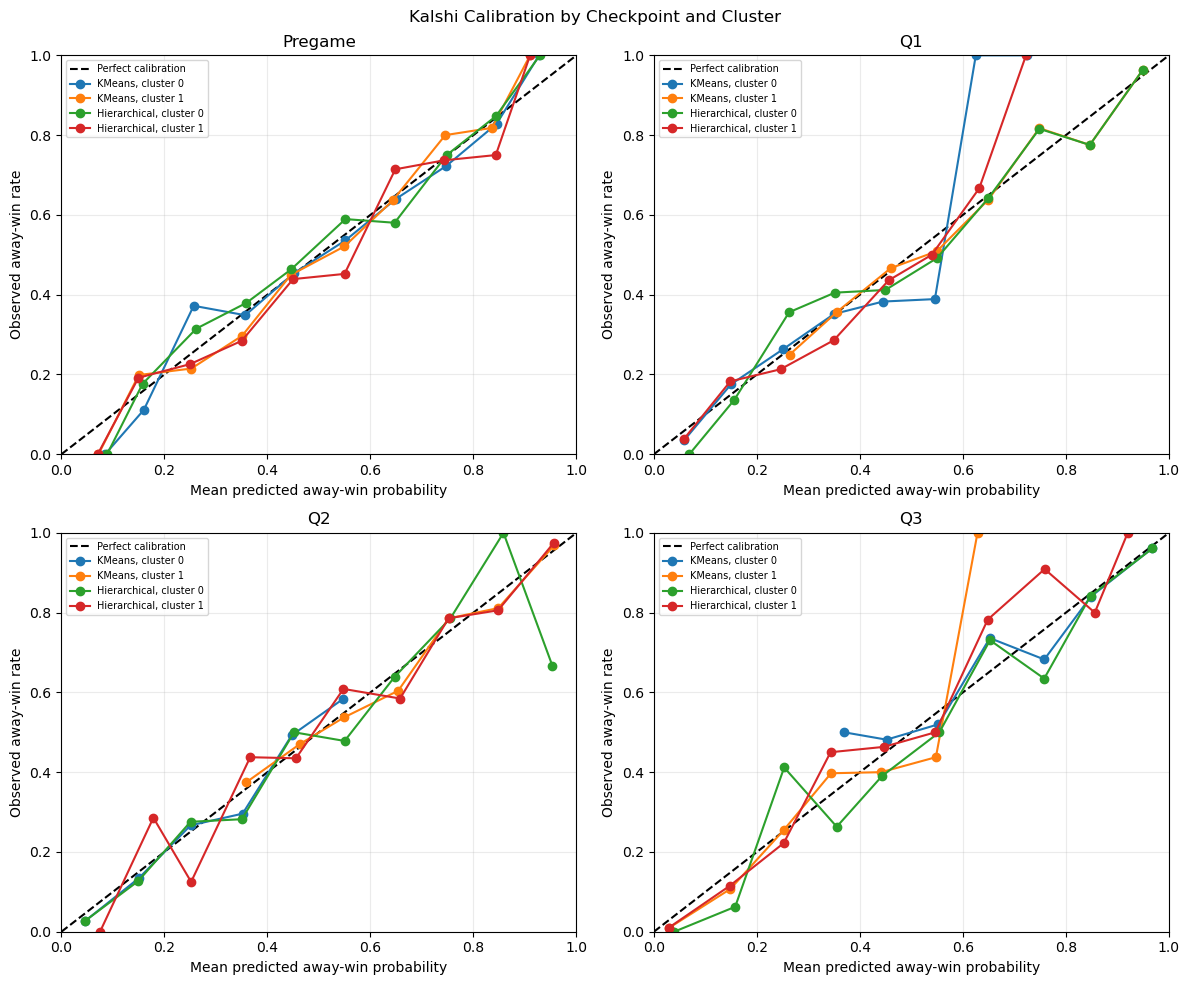

In [60]:
# ============================================================
# PART 7D: CALIBRATION CURVES
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, cp in zip(axes, ["Pregame", "Q1", "Q2", "Q3"]):
    subset = kalshi_calibration[
        (kalshi_calibration["checkpoint"] == cp)
        & (kalshi_calibration["feature_set"] == "without_favorite")
    ]

    ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")

    for method in ["KMeans", "Hierarchical"]:
        for cluster_id in [0, 1]:
            curve = subset[
                (subset["method"] == method)
                & (subset["cluster"] == cluster_id)
            ].sort_values("mean_predicted_probability")

            if curve.empty:
                continue

            ax.plot(
                curve["mean_predicted_probability"],
                curve["actual_away_win_rate"],
                marker="o",
                label=f"{method}, cluster {cluster_id}"
            )

    ax.set_title(cp)
    ax.set_xlabel("Mean predicted away-win probability")
    ax.set_ylabel("Observed away-win rate")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7)

plt.suptitle("Kalshi Calibration by Checkpoint and Cluster")
plt.tight_layout()
plt.show()

**Part 8A: Compare Forecast Performance Across Game Checkpoints**

This section creates an output directory named part8_results and consolidates the overall Kalshi forecast metrics from Part 7C into a checkpoint comparison table covering pregame, Q1, Q2, and Q3. The table includes accuracy, Brier score, log loss, mean predicted away-win probability, actual away-win rate, and calibration gap. The comparison provides a concise summary of how in-game information improves forecast quality over time.

In [62]:
# ============================================================
# PART 8A: COMPARE FORECAST PERFORMANCE ACROSS GAME CHECKPOINTS
# ============================================================

# Create output folder
output_dir = Path("part8_results")
output_dir.mkdir(exist_ok=True)

# Overall Kalshi metrics from Part 7C
checkpoint_comparison = pd.DataFrame([
    {
        "checkpoint": "Pregame",
        "accuracy": 0.6971,
        "brier_score": 0.1942,
        "log_loss": 0.5690,
        "mean_predicted_away_win": 0.4519,
        "actual_away_win_rate": 0.4457,
        "calibration_gap": 0.0062,
    },
    {
        "checkpoint": "Q1",
        "accuracy": 0.7233,
        "brier_score": 0.1806,
        "log_loss": 0.5340,
        "mean_predicted_away_win": 0.4516,
        "actual_away_win_rate": 0.4457,
        "calibration_gap": 0.0059,
    },
    {
        "checkpoint": "Q2",
        "accuracy": 0.7714,
        "brier_score": 0.1503,
        "log_loss": 0.4553,
        "mean_predicted_away_win": 0.4555,
        "actual_away_win_rate": 0.4457,
        "calibration_gap": 0.0098,
    },
    {
        "checkpoint": "Q3",
        "accuracy": 0.8335,
        "brier_score": 0.1135,
        "log_loss": 0.3516,
        "mean_predicted_away_win": 0.4544,
        "actual_away_win_rate": 0.4457,
        "calibration_gap": 0.0087,
    },
])

print("=== PART 8A: CHECKPOINT COMPARISON ===")
display(checkpoint_comparison)

=== PART 8A: CHECKPOINT COMPARISON ===


,checkpoint,accuracy,brier_score,log_loss,mean_predicted_away_win,actual_away_win_rate,calibration_gap
0,Pregame,0.6971,0.1942,0.5690,0.4519,0.4457,0.0062
1,Q1,0.7233,0.1806,0.5340,0.4516,0.4457,0.0059
2,Q2,0.7714,0.1503,0.4553,0.4555,0.4457,0.0098
3,Q3,0.8335,0.1135,0.3516,0.4544,0.4457,0.0087


**Part 8A Results**

Forecast performance improved consistently throughout the game, with accuracy increasing from 69.71% pregame to 83.35% in Q3. The Brier score decreased from 0.1942 to 0.1135, and log loss fell from 0.5690 to 0.3516, suggesting increasingly accurate probabilistic forecasts. Mean predicted away-win probabilities remained close to the actual away-win rate of 44.57% across all checkpoints, with calibration gaps ranging from 0.0059 to 0.0098. 

**Part 8B: Measuring Forecast Performance Improvements over Pregame**

This section quantifies how predictive performance changes from the pregame baseline to Q1, Q2, and Q3. It calculates the change in accuracy and the improvements in Brier score and log loss relative to pregame, where positive values indicate better performance.

In [65]:
# ============================================================
# PART 8B: MEASURING FORECAST PERFORMANCE IMPROVEMENTS OVER PREGAME
# ============================================================

baseline = checkpoint_comparison.iloc[0]

checkpoint_comparison["accuracy_change_vs_pregame"] = (
    checkpoint_comparison["accuracy"] - baseline["accuracy"]
)

checkpoint_comparison["brier_improvement_vs_pregame"] = (
    baseline["brier_score"] - checkpoint_comparison["brier_score"]
)

checkpoint_comparison["log_loss_improvement_vs_pregame"] = (
    baseline["log_loss"] - checkpoint_comparison["log_loss"]
)

print("=== PART 8B: IMPROVEMENT OVER PREGAME ===")

display(
    checkpoint_comparison[
        [
            "checkpoint",
            "accuracy",
            "accuracy_change_vs_pregame",
            "brier_improvement_vs_pregame",
            "log_loss_improvement_vs_pregame",
        ]
    ].round(4)
)

=== PART 8B: IMPROVEMENT OVER PREGAME ===


,checkpoint,accuracy,accuracy_change_vs_pregame,brier_improvement_vs_pregame,log_loss_improvement_vs_pregame
0,Pregame,0.6971,0.0000,0.0000,0.0000
1,Q1,0.7233,0.0262,0.0136,0.0350
2,Q2,0.7714,0.0743,0.0439,0.1137
3,Q3,0.8335,0.1364,0.0807,0.2174


**Part 8B Results**

Forecast performance improved substantially at each successive checkpoint compared with the pregame baseline. Accuracy increased by 2.62 percentage points in Q1, 7.43 percentage points in Q2, and 13.64 percentage points in Q3, reaching 83.35%. The Brier score improved by 0.0136, 0.0439, and 0.0807 at Q1, Q2, and Q3, respectively, while log loss improved by 0.0350, 0.1137, and 0.2174. Q3 delivered the largest gains across all three metrics.

**Part 8C: Visualize Forecast Performance Across Game Checkpoints**

This section creates three line charts to visualize Kalshi forecast performance across Pregame, Q1, Q2, and Q3. The charts display accuracy, Brier score, and log loss, highlighting that higher accuracy and lower Brier scores and log loss indicate better performance. Each chart includes labeled axes, markers, and gridlines for easier comparison.

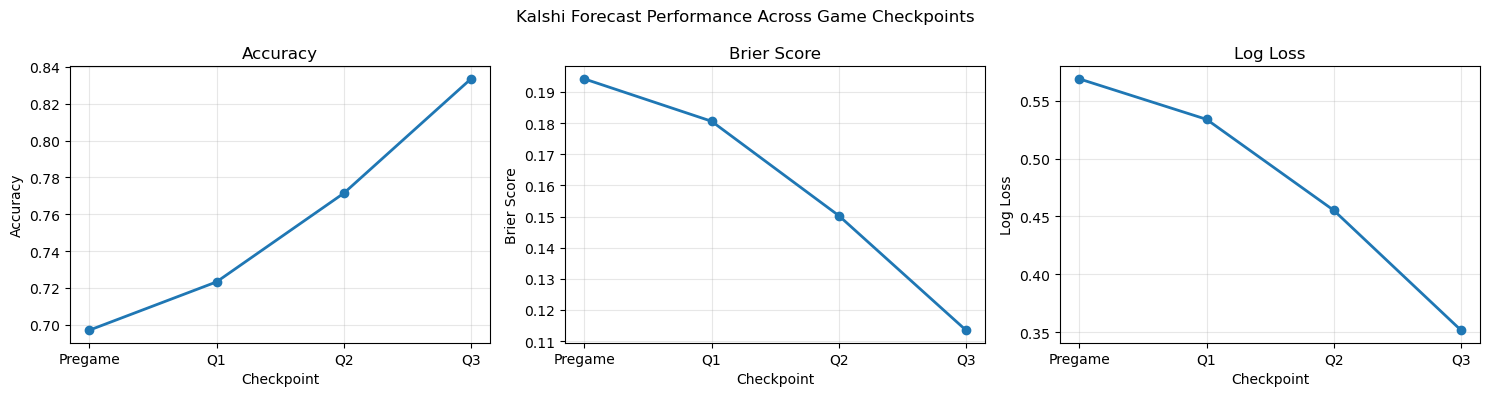

In [68]:
# ============================================================
# PART 8C: VISUALIZE FORECAST PERFORMANCE ACROSS GAME CHECKPOINTS
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ("accuracy", "Accuracy", "Accuracy"),
    ("brier_score", "Brier Score", "Brier Score"),
    ("log_loss", "Log Loss", "Log Loss"),
]

for ax, (column, title, ylabel) in zip(axes, metrics):
    ax.plot(
        checkpoint_comparison["checkpoint"],
        checkpoint_comparison[column],
        marker="o",
        linewidth=2,
    )
    ax.set_title(title)
    ax.set_xlabel("Checkpoint")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)

plt.suptitle("Kalshi Forecast Performance Across Game Checkpoints")
plt.tight_layout()
plt.savefig(
    output_dir / "checkpoint_performance.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

**8C Results**

The results show a consistent improvement in Kalshi forecast performance as NBA games progress from pregame through Q3. Accuracy increases from 69.71% pregame to 83.35% at Q3, an improvement of 13.64 percentage points. Meanwhile, the Brier Score decreases from 0.1942 to 0.1135 (a 41.6% reduction), and Log Loss falls from 0.5690 to 0.3516 (a 38.2% reduction). These improvements indicate that later-game forecasts are not only more accurate but also assign probabilities that better reflect actual outcomes. The largest improvement occurs between Q2 and Q3, suggesting that additional in-game information substantially enhances predictive performance. Overall, Q3 delivers the strongest forecasting performance among the checkpoints evaluated.